# 미션 2_호텔 예약 취소 분석

호텔 예약 데이터 **119,390건**에서 예약 취소와 관련된 요인을 찾고, 취소율을 줄이기 위한 실행 방안 제안.

<img src="images/m2_map.png" alt="미션 2 학습 지도: 준비부터 마무리까지 6단계" width="726">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 결측치가 **모르는 값**인지 **해당 없음**인지 분포로 판단하고, 의미에 맞게 처리한다
2. 업무 규칙으로 논리 오류를 점검하고, 처리 방식이 결론을 바꾸는지 **민감도**로 확인한다
3. 범주별 취소율을 **예약 수 · 신뢰구간과 함께** 보여 작은 표본의 극단값에 속지 않는다
4. 데이터가 많을 때 p값 대신 **효과 크기**로 관련성의 크기를 비교한다
5. 예약 이후 정보를 빼 **데이터 누수**를 막고, 검증 데이터로 임계값을 골라 테스트를 공정하게 평가한다

## 🧭 활용처

- **호텔 · 항공 · 공연 예약**: 취소 위험이 높은 예약을 미리 찾아 리마인드 · 보증금 정책 적용
- **이탈 예측 일반**: 구독 해지 · 장바구니 이탈처럼 "할 것인가, 안 할 것인가"를 예측하는 문제
- **데이터 품질 보고서**: 결측 해석 · 규칙 점검 · 민감도 확인을 분석 전에 정리하는 절차

## 핵심 결과

- **리드타임**: 가장 강한 신호. 당일 예약 취소율 7% → 1년 이상 전 예약 68%, 취소 위험은 예약 후 **첫 한 달**에 가장 빠르게 상승
- **과거 취소 이력**: 이력이 있으면 92%가 다시 취소. 반대로 특별 요청 · 예약 변경을 **한 번이라도** 한 고객은 취소율 절반 이하
- **주차 공간 요청**: 요청 있음 7,408건의 취소율 0% → 강한 연관 신호. 원 데이터 정의는 '고객이 요구한 주차 공간 수'이고 값이 확정된 시점은 문서로 확인되지 않음 → **시점 확인 필요 변수**로 보고 모델에서 보수적으로 제외
- **예측 모델**: 예약 시점 정보만으로 테스트 ROC-AUC 0.919, 국가를 빼도 0.886

### 데이터 구성

- **목표 변수**: `is_canceled` (1 = 취소)
- **예약 경로**: `hotel`, `market_segment`, `distribution_channel`, `agent`(여행사 ID), `company`(법인 ID)
- **도착 · 숙박**: `lead_time`(예약~도착 일수), `arrival_date_*`, `stays_in_weekend_nights`, `stays_in_week_nights`
- **고객**: `adults`, `children`, `babies`, `country`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled`
- **요청 · 변경**: `meal`, `reserved_room_type`, `booking_changes`, `days_in_waiting_list`, `required_car_parking_spaces`, `total_of_special_requests`
- **결과 이후 정보** ⚠️: `reservation_status`, `reservation_status_date`, `assigned_room_type` → 취소 여부가 정해진 뒤 기록, 원인 분석 · 예측에서 제외

---
## 0. 준비

### 0-1. 환경 설정과 데이터 불러오기

**한글 요약**

분석 · 통계 · 모델링 라이브러리를 불러오고, 한글 폰트와 그래프 색 통일. CSV 파일을 읽어 전체 크기와 앞부분 3행 확인.

**실행 흐름**

1. **입력**: `hotel_data_modified.csv` (노트북과 같은 폴더)
2. **처리**: 라이브러리 불러오기 → 출력 · 난수 설정 → 한글 폰트 · 그래프 색 지정 → CSV 읽기
3. **저장**: `raw` 원본 표, 공통 색 `BLUE` · `RED` · `GRAY`
4. **출력**: 행 × 열 크기, 앞부분 3행

In [1]:
# 라이브러리 불러오기
import numpy as np  # 신뢰구간 · 배열 계산을 위해
import pandas as pd  # 표 형태 데이터를 다루기 위해
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import seaborn as sns  # 그래프 기본 테마를 통일하기 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from matplotlib.lines import Line2D  # 범례에 점선을 넣기 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from scipy.stats import chi2_contingency, mannwhitneyu  # 범주형 · 수치형 통계 검정을 위해
from sklearn.base import clone  # 같은 설정의 학습 전 모델을 다시 만들기 위해
from sklearn.compose import ColumnTransformer  # 수치형 · 범주형 전처리를 나눠 적용하기 위해
from sklearn.ensemble import RandomForestClassifier  # 비선형 관계까지 학습하기 위해
from sklearn.inspection import permutation_importance  # 변수 중요도를 측정하기 위해
from sklearn.linear_model import LogisticRegression  # 비교 기준이 되는 선형 모델을 쓰기 위해
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay  # 평가 결과를 그래프로 보기 위해
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score  # 평가 지표를 계산하기 위해
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split  # 데이터 분할 · 교차검증을 위해
from sklearn.pipeline import Pipeline  # 전처리 + 모델을 묶어 검증 데이터 누수를 막기 위해
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # 범주형 인코딩 · 수치형 표준화를 위해

# 기본 설정
pd.set_option("display.max_columns", 40)  # 29개 컬럼을 생략 없이 보기 위해
RANDOM_STATE = 42  # 분할 · 모델 결과를 재현하기 위해

# 그래프 스타일
sns.set_theme(style="whitegrid")  # 흰 배경 + 격자로 값을 읽기 쉽게 하기 위해
installed = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록
BLUE, RED, GRAY = "#2a78d6", "#d03b3b", "#b9b7ae"  # 모든 그래프의 의미를 같은 색으로 맞추기 위해 (기본 · 강조 · 신뢰 낮음)

# 데이터 불러오기
raw = pd.read_csv("hotel_data_modified.csv")  # 처리 전후 비교를 위해 원본을 그대로 보존
print(f"{raw.shape[0]:,}행 × {raw.shape[1]}열")  # 데이터 규모를 확인하기 위해
raw.head(3)  # 컬럼 값의 형태를 확인하기 위해

119,390행 × 29열


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,NaN,NaN,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,NaN,NaN,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,NaN,NaN,0,0,0,Check-Out,2015-07-02


**결과 해설**

```
119,390행 × 29열   : 예약 119,390건, 컬럼 29개
agent · company NaN : 여행사 · 법인을 거치지 않은 예약 → 1-1에서 의미 해석
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| read_csv() · set_option() | pandas | CSV → 표 · 출력 옵션 | `pd.read_csv("hotel_data_modified.csv")` |
| shape · head() | pandas.DataFrame | (행, 열) 크기 · 앞부분 | `raw.shape[0]` · `raw.head(3)` |
| set_theme() | seaborn | 그래프 기본 테마 | `sns.set_theme(style="whitegrid")` |
| fontManager.ttflist · rcParams | matplotlib | 폰트 목록 · 전역 설정 | `plt.rcParams["font.family"] = font` |
| print() | Python 내장 함수 | 데이터 규모 출력 | `print(f"{raw.shape[0]:,}행 ...")` |
| import · for · if · break | Python 기본 문법 | 불러오기 · 한글 폰트 탐색 | `for font in [...]:` |

---
## 1. 데이터 품질 점검

### 1-1. 결측치 현황과 의미 확인

**한글 요약**

- 컬럼별 결측 수 · 결측률 계산
- `agent` · `company` 결측이 **모르는 값**인지 **해당 없음**인지 시장 세그먼트별 결측률로 확인
- 결측 대체값 0의 충돌 여부, `country` 결측의 호텔 쏠림 점검

<img src="images/m2_missing.png" alt="결측 컬럼 4개의 근거 · 의미 · 처리" width="837">

**실행 흐름**

1. **입력**: 원본 `raw`
2. **처리**: 컬럼별 결측 수 · 결측률 → 시장 세그먼트별 agent · company 결측률 → ID 0 사용 여부 · country 결측의 호텔 분포
3. **저장**: `missing` · `segment_missing`
4. **출력**: 결측 표 2개, 대체값 충돌 · 쏠림 확인 문장

In [2]:
# 컬럼별 결측 현황
missing_count = raw.isna().sum()  # 어느 컬럼에 결측이 있는지 보기 위해
missing_rate = (missing_count / len(raw) * 100).round(2)  # 규모를 비교하기 위해 전체 대비 비율(%)
missing = pd.DataFrame({"결측 수": missing_count, "결측률(%)": missing_rate})  # 개수와 비율을 한 표로 보기 위해
display(missing[missing["결측 수"] > 0].sort_values("결측 수", ascending=False))  # 결측 있는 컬럼만 많은 순으로 보기 위해

# 시장 세그먼트별 결측률
segment_missing = (
    raw.groupby("market_segment")  # 결측이 특정 예약 경로에 몰리는지 보기 위해
    .agg(
        예약수=("is_canceled", "size"),  # 세그먼트 규모를 함께 보기 위해
        agent_결측률=("agent", lambda s: s.isna().mean() * 100),  # 여행사를 거치지 않은 비율을 보기 위해
        company_결측률=("company", lambda s: s.isna().mean() * 100),  # 법인 외 예약 비율을 보기 위해
    )
    .sort_values("예약수", ascending=False)  # 규모가 큰 세그먼트부터 보기 위해
    .round(1)  # 읽기 쉽도록 소수 첫째 자리
)
display(segment_missing)  # 결측이 특정 경로에 몰리는지 확인하기 위해

# 결측 처리 방법 판단 근거
agent_uses_0 = 0 in set(raw["agent"].dropna())  # 0을 결측 대체값으로 써도 기존 ID와 겹치지 않는지 확인하기 위해
company_uses_0 = 0 in set(raw["company"].dropna())  # 법인 ID도 같은 방식으로 확인하기 위해
resort_share = raw.loc[raw["country"].isna(), "hotel"].eq("Resort Hotel").mean()  # country 결측이 한 호텔에 몰리는지 보기 위해
print("ID 0 사용 여부 → agent:", agent_uses_0, "/ company:", company_uses_0)  # 대체값 충돌 여부를 확인하기 위해
print(f"country 결측 중 Resort Hotel 비율: {resort_share:.1%}")  # 결측 쏠림을 확인하기 위해

,결측 수,결측률(%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


,예약수,agent_결측률,company_결측률
market_segment,,,
Online TA,56477,0.6,99.8
Offline TA/TO,24219,1.6,99.6
Groups,19811,20.9,93.0
Direct,12606,47.7,98.3
Corporate,5295,86.8,15.6
Complementary,743,86.1,57.9
Aviation,237,89.5,10.5
Undefined,2,100.0,100.0


ID 0 사용 여부 → agent: False / company: False
country 결측 중 Resort Hotel 비율: 95.1%


**결과 해설**

```
company 94.31%               : 대부분 법인 예약이 아님
agent 13.69%                 : 여행사 채널 결측 1% 안팎, 직접 · 법인 · 항공 결측 47.7~89.5%
ID 0 사용 여부 False         : 0을 '없음'으로 써도 기존 ID와 겹치지 않음
country 결측 중 Resort 95.1% : 특정 호텔에 몰린 결측 → 지우면 편향 발생
```

- `agent`: 결측 = **여행사를 거치지 않은 예약** → 0으로 채우고 `has_agent` 플래그 생성
- `company`: 결측 = **법인 예약이 아님** → 0으로 채우고 `has_company` 플래그 생성
- `country`: 결측 488건 중 95%가 Resort Hotel → `Unknown` 범주로 유지
- `children`: 4건(0.003%)뿐, 92.8%가 0명 → 0으로 채움

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DataFrame() | pandas | 개수 · 비율을 한 표로 | `pd.DataFrame({"결측 수": ..., ...})` |
| isna() · sum() · groupby() · agg()<br>loc[] · sort_values() · round() | pandas.DataFrame | 결측 개수 · 세그먼트별 집계<br>조건 선택 · 정렬 · 반올림 | `raw.groupby("market_segment").agg(...)`<br>`raw.loc[raw["country"].isna(), "hotel"]` |
| mean() · dropna() · eq() | pandas.Series | 결측 비율 · 결측 제거 · 같은 값 | `s.isna().mean()` · `.eq("Resort Hotel")` |
| display() | IPython.display | 셀 중간 표 출력 | `display(segment_missing)` |
| len() · set() · print() | Python 내장 함수 | 행 수 · 값 집합 · 출력 | `set(raw["agent"].dropna())` |
| lambda · in | Python 기본 문법 | 한 줄 함수 · 포함 검사 | `lambda s: s.isna().mean() * 100` |

### 1-2. 결측치 처리와 파생 변수 생성

**한글 요약**

- 1-1 해석대로 결측 처리, 여행사 · 법인 경유 여부 플래그 생성
- 규칙 점검 · 분석용 **날짜 · 총 숙박일수 · 총 인원** 파생 변수 추가
- `meal`의 `Undefined` · `SC`: 모두 식사 미포함 → `SC`로 통일
- 완전 중복 행 3만여 건: **예약 ID가 없어 같은 조건의 다른 예약**일 수 있으므로 유지

**실행 흐름**

1. **입력**: 원본 `raw`
2. **처리**: 결측 처리 · 플래그 → meal 표기 통일 → 날짜 변환 → 총 숙박일수 · 총 인원 계산
3. **저장**: `df` (원본은 그대로)
4. **출력**: 결측 0건 검증, 유지한 중복 행 수

In [3]:
# 결측 처리
df = raw.copy()  # 처리 전후를 비교하기 위해 원본은 보존
df["children"] = df["children"].fillna(0).astype(int)  # 결측 4건을 최빈값 0명으로 채우기 위해
df["country"] = df["country"].fillna("Unknown")  # 지우면 리조트 쪽으로 편향되므로 별도 범주로 남기기 위해
df["has_agent"] = df["agent"].notna().astype(int)  # 결측 자체가 정보이므로 여행사 경유 여부로 남기기 위해
df["has_company"] = df["company"].notna().astype(int)  # 법인 예약 여부를 변수로 쓰기 위해
df[["agent", "company"]] = df[["agent", "company"]].fillna(0).astype(int)  # 쓰이지 않는 ID 0으로 '없음'을 표시하기 위해
df["meal"] = df["meal"].replace("Undefined", "SC")  # 같은 의미(식사 미포함)를 한 표기로 합치기 위해

# 날짜 파생 변수
year = df["arrival_date_year"].astype(str)  # 문자열로 이어 붙이기 위해
day = df["arrival_date_day_of_month"].astype(str)  # 문자열로 이어 붙이기 위해
arrival_text = year + "-" + df["arrival_date_month"] + "-" + day  # 날짜로 바꿀 수 있는 형태(예: 2015-July-1)로 만들기 위해
df["arrival_date"] = pd.to_datetime(arrival_text, format="%Y-%B-%d", errors="coerce")  # 존재하지 않는 날짜는 NaT로 표시하기 위해
df["status_date"] = pd.to_datetime(df["reservation_status_date"], errors="coerce")  # 날짜 규칙을 점검하기 위해 상태 확정일 변환

# 숙박 · 인원 파생 변수
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]  # 체크아웃 예정일 계산 · 분석에 쓰기 위해
df["total_guests"] = df["adults"] + df["children"] + df["babies"]  # 투숙객 0명 예약을 찾기 위해

# 결과 검증
assert df[["children", "country", "agent", "company"]].notna().all().all()  # 처리한 4개 컬럼에 결측이 남지 않았는지 확인하기 위해
print(f"결측 처리 완료 · 중복 행 {raw.duplicated().sum():,}건은 유지")  # 예약 ID가 없어 삭제를 보류했음을 기록하기 위해

결측 처리 완료 · 중복 행 33,103건은 유지

**결과 해설**

```
결측 처리 완료        : 처리 대상 4개 컬럼 결측 0건 (assert 통과)
중복 행 33,103건 유지 : 예약 ID 없이 지우면 결과 왜곡 → 1-6에서 영향 확인
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| to_datetime() | pandas | 문자열 → 날짜, 오류는 NaT | `pd.to_datetime(..., format="%Y-%B-%d", errors="coerce")` |
| copy() · duplicated() | pandas.DataFrame | 독립 복사본 · 중복 행 여부 | `raw.copy()` · `raw.duplicated().sum()` |
| fillna() · astype() · notna()<br>replace() · all() | pandas.DataFrame / Series | 결측 채우기 · 형 변환 · 결측 아님<br>값 바꾸기 · 모두 True | `fillna(0).astype(int)`<br>`notna().all().all()` |
| assert · print() | Python 기본 문법 · 내장 함수 | 결측 0건 검사 · 출력 | `assert df[[...]].notna().all().all()` |

### 1-3. 인원 이상치: IQR 기준 적용 가능성 확인

**한글 요약**

- 인원 컬럼에 IQR 상한(Q3 + 1.5×IQR)을 적용했을 때 이상치로 잡히는 비율 확인
- 값이 0~2명에 몰려 IQR 폭이 0이 되면 **정상 예약 대량 오탐** → 업무 기준(성인 10명 · 어린이 5명 · 아기 5명 초과) 사용

**실행 흐름**

1. **입력**: `df`의 `adults` · `children` · `babies`
2. **처리**: Q1 · Q3 → IQR 상한 → 상한 초과 예약 비율
3. **저장**: `iqr_fence`
4. **출력**: 컬럼별 상한, 초과 비율

In [4]:
# IQR 상한 계산
people = df[["adults", "children", "babies"]]  # 인원 관련 3개 컬럼만 보기 위해
q1, q3 = people.quantile(0.25), people.quantile(0.75)  # IQR을 구하기 위해 하위 · 상위 25% 경계
iqr_fence = q3 + 1.5 * (q3 - q1)  # 일반적인 이상치 상한을 적용해 보기 위해
print("IQR 상한:", iqr_fence.to_dict())  # 컬럼별 상한을 확인하기 위해

# 상한 초과 비율
over_ratio = (people > iqr_fence).any(axis=1).mean()  # 3개 중 하나라도 넘는 예약 비율로 오탐 규모를 보기 위해
print(f"IQR 상한을 넘는 예약: {over_ratio:.1%}  ← 이상치로 보기엔 너무 많다")  # IQR 기준을 쓸 수 없는 근거를 남기기 위해

IQR 상한: {'adults': 2.0, 'children': 0.0, 'babies': 0.0}
IQR 상한을 넘는 예약: 12.6%  ← 이상치로 보기엔 너무 많다


**결과 해설**

```
IQR 상한 adults 2.0, children · babies 0.0 : 값이 0~2명에 몰려 IQR 폭이 0
IQR 상한 초과 12.6%                        : 성인 3명 또는 어린이 1명만 있어도 이상치 → 오탐
결론                                       : IQR 대신 업무 기준(10 · 5 · 5명) 사용 (1-4)
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| quantile() · any() · mean() · to_dict() | pandas.DataFrame / Series | 분위수 · 하나라도 True · 비율 · 딕셔너리 | `(people > iqr_fence).any(axis=1).mean()` |
| print() | Python 내장 함수 | 결과 출력 | `print("IQR 상한:", ...)` |
| 튜플 언패킹 | Python 기본 문법 | 값 2개를 한 번에 저장 | `q1, q3 = ...` |

### 1-4. 논리 오류: 규칙 10개로 점검

**한글 요약**

- 상식 · 업무 규칙에 어긋나는 예약을 10개 규칙으로 점검
- 규칙마다 **위반 여부(True/False) · 처리 방법 · 근거**를 함께 저장, 위반 건수 · 비율을 표로 정리

**실행 흐름**

1. **입력**: `df` (1-2 파생 변수 포함)
2. **처리**: 예약일 · 체크아웃 예정일 계산 → 규칙 10개 정의 → 규칙별 위반 건수 · 비율 집계
3. **저장**: `rules` (규칙명 → 위반 여부 · 처리 · 근거), `rule_report`
4. **출력**: 규칙 10개 점검 표

In [5]:
# 비교용 날짜
booking_date = df["arrival_date"] - pd.to_timedelta(df["lead_time"], unit="D")  # 상태 확정일과 비교하기 위해 예약일 = 도착일 - 리드타임
expected_checkout = df["arrival_date"] + pd.to_timedelta(df["total_nights"], unit="D")  # Check-Out 날짜와 비교하기 위해
status = df["reservation_status"]  # 상태별 규칙을 짧게 쓰기 위해 (Check-Out · Canceled · No-Show)

# 규칙 정의: 규칙명 → (위반 여부, 처리, 근거)
rules = {  # 규칙명으로 위반 여부 · 처리 · 근거를 찾기 위해
    "투숙객 0명": (df["total_guests"].eq(0), "제거", "사람이 없는 예약은 성립하지 않음"),  # 인원 합계로 빈 예약을 찾기 위해
    "성인 없이 아기만 투숙": (df["babies"].gt(0) & df["adults"].eq(0), "제거", "아기 단독 투숙은 불가능"),  # 보호자 없는 예약을 찾기 위해
    "인원 극단값": (df["adults"].gt(10) | df["children"].gt(5) | df["babies"].gt(5), "제거", "업무 기준(10·5·5명) 초과"),  # IQR 대신 업무 기준으로 극단값을 찾기 위해 (1-3)
    "Check-Out인데 확정일 ≠ 체크아웃 예정일": (  # 줄이 길어 조건을 다음 줄에 쓰기 위해
        status.eq("Check-Out") & df["status_date"].ne(expected_checkout), "제거", "상태와 날짜 중 하나가 오류"),  # 체크아웃 기록과 날짜가 맞는지 보기 위해
    "No-Show인데 확정일 ≠ 도착일": (  # 줄이 길어 조건을 다음 줄에 쓰기 위해
        status.eq("No-Show") & df["status_date"].ne(df["arrival_date"]), "제거", "노쇼는 도착일에 확정되어야 함"),  # 노쇼 기록과 날짜가 맞는지 보기 위해
    "재방문 플래그 모순": (  # 줄이 길어 조건을 다음 줄에 쓰기 위해
        df["is_repeated_guest"].eq(0) & df["previous_bookings_not_canceled"].gt(0), "보정 (→ 1)", "정상 이용 이력이 있으면 재방문 고객"),  # 지우지 않고 플래그만 바로잡기 위해
    "대기일수 > 리드타임": (df["days_in_waiting_list"].gt(df["lead_time"]), "-", "대기는 예약~도착 사이에 있어야 함"),  # 대기 기간이 가능한 범위인지 보기 위해
    "상태 확정일 < 예약일": (df["status_date"].lt(booking_date), "-", "예약 전에 상태가 정해질 수 없음"),  # 날짜 순서가 맞는지 보기 위해
    "취소 확정일 > 도착일": (status.eq("Canceled") & df["status_date"].gt(df["arrival_date"]), "-", "도착 후에는 취소가 아닌 노쇼"),  # 취소와 노쇼가 섞이지 않았는지 보기 위해
    "존재하지 않는 날짜": (df["arrival_date"].isna() | df["status_date"].isna(), "-", "2월 30일 같은 날짜"),  # 1-2에서 NaT가 된 날짜를 찾기 위해
}  # 위반 여부와 처리 · 근거를 한곳에 묶어 표와 정제에 함께 쓰기 위해

# 규칙별 위반 집계
report_rows = []  # 규칙 1개를 표 1행으로 모으기 위해
for name, (mask, action, reason) in rules.items():  # 규칙을 하나씩 집계하기 위해 (mask: 위반 행이면 True)
    report_rows.append({  # 규칙 결과를 표의 한 행으로 쌓기 위해
        "규칙": name,  # 어떤 규칙인지 보이기 위해
        "위반 건수": int(mask.sum()),  # True 개수로 위반 건수를 세기 위해
        "비율(%)": round(mask.mean() * 100, 3),  # 규모를 비교하기 위해 전체 대비 비율
        "처리": action,  # 어떻게 처리할지 함께 보이기 위해
        "근거": reason,  # 처리 근거를 남기기 위해
    })  # 행 하나를 완성하기 위해
rule_report = pd.DataFrame(report_rows)  # 점검 결과를 표로 보기 위해
rule_report  # 규칙 10개 결과를 출력하기 위해

,규칙,위반 건수,비율(%),처리,근거
0,투숙객 0명,180,0.151,제거,사람이 없는 예약은 성립하지 않음
1,성인 없이 아기만 투숙,3,0.003,제거,아기 단독 투숙은 불가능
2,인원 극단값,15,0.013,제거,업무 기준(10·5·5명) 초과
3,Check-Out인데 확정일 ≠ 체크아웃 예정일,27,0.023,제거,상태와 날짜 중 하나가 오류
4,No-Show인데 확정일 ≠ 도착일,1,0.001,제거,노쇼는 도착일에 확정되어야 함
5,재방문 플래그 모순,782,0.655,보정 (→ 1),정상 이용 이력이 있으면 재방문 고객
6,대기일수 > 리드타임,0,0.000,-,대기는 예약~도착 사이에 있어야 함
7,상태 확정일 < 예약일,0,0.000,-,예약 전에 상태가 정해질 수 없음
8,취소 확정일 > 도착일,0,0.000,-,도착 후에는 취소가 아닌 노쇼
9,존재하지 않는 날짜,0,0.000,-,2월 30일 같은 날짜


**결과 해설**

```
투숙객 0명 180건         : 제거 대상 중 가장 많음
재방문 플래그 모순 782건 : 행은 유지, 플래그만 1로 보정 (1-5)
규칙 7~10 0건            : 날짜 순서 · 존재하지 않는 날짜 오류 없음
```

- **성인 없이 어린이만 있는 예약**(223건): 어린이 나이 기준이 정의되지 않아 유지
- **재방문 플래그 모순**: 과거 정상 이용 횟수는 관측된 사실, 플래그는 갱신 누락 가능성이 더 큼 → 플래그만 보정

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| to_timedelta() · DataFrame() | pandas | 숫자 → 기간(일) · 표 | `pd.to_timedelta(df["lead_time"], unit="D")` |
| eq() · ne() · gt() · lt()<br>isna() · sum() · mean() | pandas.Series | 같음 · 다름 · 큼 · 작음<br>NaT 여부 · 건수 · 비율 | `status.eq("Check-Out")`<br>`mask.sum()` |
| int() · round() | Python 내장 함수 | 정수 변환 · 반올림 | `round(mask.mean() * 100, 3)` |
| & · \| · dict<br>for ... in .items() | Python 기본 문법 | 조건 AND · OR · 규칙 묶음<br>규칙 하나씩 꺼내기 | `df["babies"].gt(0) & df["adults"].eq(0)`<br>`for name, (mask, action, reason) in rules.items():` |

### 1-5. 오류 행 제거 · 보정과 재검증

**한글 요약**

- 처리가 `제거`인 규칙 중 하나라도 위반한 행 제거, 재방문 플래그 모순은 1로 보정
- 정제 후 **위반 0건**을 `assert`로 재검증

<img src="images/m2_clean.png" alt="원본 119,390행에서 정제본 119,165행까지" width="929">

**실행 흐름**

1. **입력**: `df` · 1-4의 `rules`
2. **처리**: 제거 규칙 위반 여부 결합 → 위반 행 제외 → 재방문 플래그 보정 → 위반 0건 재검증
3. **저장**: `clean` 정제본 (2장 이후 분석에 사용)
4. **출력**: 제거 · 보정 · 보존 건수

In [6]:
# 제거 대상 표시
remove_masks = [mask for mask, action, _ in rules.values() if action == "제거"]  # 처리가 '제거'인 규칙 5개만 모으기 위해
drop_mask = pd.concat(remove_masks, axis=1).any(axis=1)  # 5개 중 하나라도 위반한 행을 찾기 위해

# 정제
clean = df.loc[~drop_mask].copy()  # 위반하지 않은 행만 분석에 쓰기 위해
clean.loc[clean["previous_bookings_not_canceled"].gt(0), "is_repeated_guest"] = 1  # 정상 이용 이력이 있으면 재방문 고객으로 바로잡기 위해

# 재검증
assert clean["total_guests"].gt(0).all()  # 투숙객 0명 예약이 남지 않았는지 확인하기 위해
assert not (clean["is_repeated_guest"].eq(0) & clean["previous_bookings_not_canceled"].gt(0)).any()  # 플래그 모순이 없어졌는지 확인하기 위해
assert not drop_mask.loc[clean.index].any()  # 제거 대상이 남지 않았는지 확인하기 위해
fixed = rules["재방문 플래그 모순"][0].sum()  # 보정한 행 수를 보고하기 위해
print(f"제거 {drop_mask.sum():,}건 · 재방문 플래그 보정 {fixed:,}건 · 최종 {len(clean):,}행 ({len(clean) / len(df):.2%} 보존)")  # 정제 규모를 기록하기 위해
print("✅ 통과")  # 재검증을 통과했음을 보이기 위해

제거 225건 · 재방문 플래그 보정 782건 · 최종 119,165행 (99.81% 보존)
✅ 통과


**결과 해설**

```
제거 225건     : 제거 규칙 5개 위반 합계 226건 중 1건이 두 규칙에 중복 위반
보정 782건     : 재방문 플래그만 1로 수정
최종 119,165행 : 원본의 99.81% 보존
통과           : 정제 후 모든 위반 0건
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| concat() | pandas | 여러 Series를 열 방향으로 | `pd.concat(remove_masks, axis=1)` |
| any() · loc[] · copy() · index | pandas.DataFrame | 하나라도 True · 조건 선택 · 복사 · 행 번호 | `df.loc[~drop_mask].copy()` |
| ~ · 조건 컴프리헨션<br>assert · not | Python 기본 문법 | True ↔ False 반전 · 조건 목록<br>검사 · 부정 | `~drop_mask`<br>`assert not (...).any()` |
| len() · print() | Python 내장 함수 | 행 수 · 출력 | `len(clean) / len(df)` |

### 1-6. 처리 방식별 민감도 확인

**한글 요약**

처리 방식에 따라 핵심 지표(취소율)가 달라지는지 비교. 원본 · 정제본 · 중복 행까지 제거한 경우의 행 수와 취소율 확인.

**실행 흐름**

1. **입력**: `df` · `clean`
2. **처리**: 시나리오 3개 정의 → 시나리오별 행 수 · 취소율
3. **저장**: `sensitivity_rows`
4. **출력**: 시나리오 비교 표

In [7]:
# 비교 시나리오
scenarios = {
    "원본": df,  # 처리 전 기준을 보기 위해
    "정제본 (분석 사용)": clean,  # 실제 분석에 쓰는 데이터를 보기 위해
    "중복 행까지 제거 (참고)": df.drop_duplicates(subset=raw.columns),  # 중복 삭제의 영향을 보기 위해 원본 29개 컬럼 기준
}

# 시나리오별 취소율
sensitivity_rows = []  # 시나리오 1개를 표 1행으로 모으기 위해
for name, data in scenarios.items():  # 시나리오를 하나씩 계산하기 위해
    sensitivity_rows.append({
        "시나리오": name,  # 어떤 처리인지 보이기 위해
        "행 수": f"{len(data):,}",  # 규모를 읽기 쉽도록 천 단위 쉼표
        "취소율": f"{data['is_canceled'].mean():.2%}",  # 0/1 평균으로 취소 비율을 구하기 위해
    })
pd.DataFrame(sensitivity_rows).set_index("시나리오")  # 시나리오 이름을 행 이름으로 보기 위해

,행 수,취소율
시나리오,,
원본,"119,390",37.04%
정제본 (분석 사용),"119,165",37.08%
중복 행까지 제거 (참고),"86,287",27.69%


**결과 해설**

```
원본 37.04% → 정제본 37.08% : 오류 행 제거의 영향 거의 없음 → 결론에 영향 없음
중복 제거 시 27.69%         : 취소율 약 9.4%p 하락 → 예약 ID 없이 중복을 지우면 결과 왜곡
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| DataFrame() · set_index() | pandas | 표 · 행 이름 지정 | `pd.DataFrame(sensitivity_rows).set_index("시나리오")` |
| drop_duplicates() · columns | pandas.DataFrame | 중복 행 제거 · 컬럼 목록 | `df.drop_duplicates(subset=raw.columns)` |
| mean() · len() | pandas.Series · 내장 함수 | 취소율 · 행 수 | `data['is_canceled'].mean()` |
| f-string 서식 | Python 기본 문법 | 천 단위 쉼표 · 백분율 | `f"{len(data):,}"` · `f"{...:.2%}"` |

---
## 2. 탐색적 분석

### 2-1. 분석 기준값과 범주별 취소율 함수

**한글 요약**

- 전체 취소율(그래프의 빨간 점선)과 신뢰 기준 예약 수 정의
- 범주별 **예약 수 · 취소율 · 95% 신뢰구간** 계산 함수를 만들어 2장 전체에서 재사용
- 예약 수가 적은 범주는 우연히 0% 또는 100%가 나와 중요해 보일 수 있음 → 모든 그래프에 예약 수 함께 표시

**실행 흐름**

1. **입력**: 정제본 `clean`
2. **처리**: 전체 취소율 · 최소 예약 수 정의 → 범주별 집계 함수 (표준오차로 95% 신뢰구간)
3. **저장**: `BASE` · `MIN_N` · `rate_table` 함수
4. **출력**: 전체 예약 · 취소 건수 · 취소율

In [8]:
# 기준값
BASE = clean["is_canceled"].mean()  # 모든 그래프에 같은 기준선을 그리기 위해 전체 취소율
MIN_N = 500  # 예약 수가 적어 흔들리는 범주를 표시하기 위해

# 범주별 취소율 함수
def rate_table(key: pd.Series) -> pd.DataFrame:  # 2장 전체에서 같은 방식으로 계산하기 위해 함수로
    """범주별 예약 수 · 취소율 · 95% 신뢰구간"""
    g = clean.groupby(key, observed=True)["is_canceled"].agg(예약수="size", 취소율="mean")  # 범주별 규모와 취소 비율을 함께 보기 위해
    se = np.sqrt(g["취소율"] * (1 - g["취소율"]) / g["예약수"])  # 예약 수가 적을수록 커지는 불확실성을 재기 위해 표준오차
    g["95% 하한"] = (g["취소율"] - 1.96 * se).clip(0, 1)  # 신뢰구간 하한이 0 아래로 내려가지 않도록
    g["95% 상한"] = (g["취소율"] + 1.96 * se).clip(0, 1)  # 신뢰구간 상한이 1을 넘지 않도록
    return g  # 2장 그래프 · 5장 요약에 다시 쓰기 위해

# 데이터 규모 확인
print(f"전체 예약 {len(clean):,}건 · 취소 {clean['is_canceled'].sum():,}건 · 전체 취소율 {BASE:.1%}")  # 기준값을 확인하기 위해

전체 예약 119,165건 · 취소 44,184건 · 전체 취소율 37.1%


**결과 해설**

```
전체 예약 119,165건 : 정제본 기준
취소 44,184건       : is_canceled = 1인 예약
전체 취소율 37.1%   : 2장 모든 그래프의 기준선
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| rate_table() | 사용자 정의 함수 | 범주별 예약 수 · 취소율 · 신뢰구간 | `def rate_table(key):` |
| groupby() · agg() | pandas.DataFrame | 범주별 size · mean 동시 계산 | `clean.groupby(key, observed=True)[...].agg(...)` |
| mean() · sum() · clip() | pandas.Series | 취소율 · 취소 건수 · 0~1 제한 | `.clip(0, 1)` |
| sqrt() | numpy | 제곱근 | `np.sqrt(...)` |
| def · return · 타입 힌트 | Python 기본 문법 | 함수 정의 · 입출력 자료형 표시 | `key: pd.Series) -> pd.DataFrame` |

### 2-2. 이진 변수: 있다 vs 없다

**한글 요약**

9개 이진 변수(있음/없음)별 취소율 비교. **아령 그래프**로 두 점 사이 거리(효과 크기)를 한눈에 표시하고, 차이가 큰 순서로 정렬.

<img src="images/m2_leak.png" alt="주차 공간 요청 취소율 0%와 값 확정 시점 확인 필요" width="837">

**실행 흐름**

1. **입력**: `clean`의 이진 변수 9개
2. **처리**: 변수별 없음 · 있음 취소율 → 차이(%p) 큰 순 정렬 → 아령 그래프
3. **저장**: `binary_summary` (5장에서 재사용)
4. **출력**: 아령 그래프, 요약 표

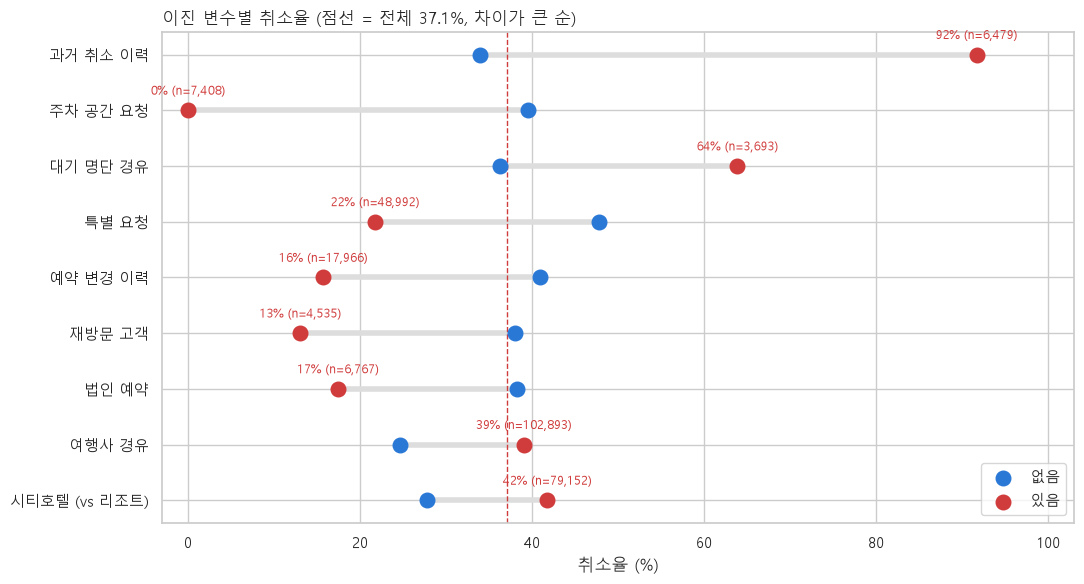

,없음 취소율,있음 취소율,있음 예약수,차이(%p)
변수,,,,
과거 취소 이력,33.9%,91.7%,"6,479",+57.7
주차 공간 요청,39.5%,0.0%,"7,408",-39.5
대기 명단 경유,36.2%,63.9%,"3,693",+27.7
특별 요청,47.8%,21.8%,"48,992",-26.0
예약 변경 이력,40.9%,15.7%,"17,966",-25.1
재방문 고객,38.0%,13.1%,"4,535",-25.0
법인 예약,38.3%,17.5%,"6,767",-20.8
여행사 경유,24.6%,39.0%,"102,893",+14.4
시티호텔 (vs 리조트),27.8%,41.8%,"79,152",+14.0


In [9]:
# 이진 변수 정의 (True = 있음)
binary = {
    "시티호텔 (vs 리조트)": clean["hotel"].eq("City Hotel"),
    "재방문 고객": clean["is_repeated_guest"].eq(1),
    "과거 취소 이력": clean["previous_cancellations"].gt(0),
    "예약 변경 이력": clean["booking_changes"].gt(0),
    "여행사 경유": clean["has_agent"].eq(1),
    "법인 예약": clean["has_company"].eq(1),
    "주차 공간 요청": clean["required_car_parking_spaces"].gt(0),
    "특별 요청": clean["total_of_special_requests"].gt(0),
    "대기 명단 경유": clean["days_in_waiting_list"].gt(0),
}  # 여러 변수를 같은 방식으로 비교하기 위해 이름 → 있음 여부로 묶음

# 변수별 없음 · 있음 취소율
rows = []  # 변수 1개를 표 1행으로 모으기 위해
for name, flag in binary.items():  # 변수를 하나씩 계산하기 위해
    t = rate_table(flag.astype(int))  # 0 = 없음, 1 = 있음으로 나눠 취소율을 구하기 위해
    rows.append({
        "변수": name,  # 어떤 변수인지 보이기 위해
        "없음 취소율": t.loc[0, "취소율"],  # 비교 기준을 보이기 위해
        "있음 취소율": t.loc[1, "취소율"],  # 비교 대상을 보이기 위해
        "있음 예약수": int(t.loc[1, "예약수"]),  # 있음 쪽 신뢰도를 판단하기 위해
        "차이(%p)": (t.loc[1, "취소율"] - t.loc[0, "취소율"]) * 100,  # 효과 크기를 %p로 보기 위해
    })
binary_summary = pd.DataFrame(rows).set_index("변수").sort_values("차이(%p)", key=abs, ascending=False)  # 방향과 무관하게 차이가 큰 순으로 보기 위해

# 아령 그래프
plot_df = binary_summary.iloc[::-1]  # 차이가 큰 변수가 위쪽에 오도록 순서를 뒤집기 위해
y = np.arange(len(plot_df))  # 변수별 세로 위치를 정하기 위해
fig, ax = plt.subplots(figsize=(11, 6))  # 그래프 영역을 만들기 위해
ax.hlines(y, plot_df["없음 취소율"] * 100, plot_df["있음 취소율"] * 100, color="#ddd", linewidth=4, zorder=1)  # 선 길이로 효과 크기를 보이기 위해
ax.scatter(plot_df["없음 취소율"] * 100, y, s=110, color=BLUE, zorder=3, label="없음")  # 없음 쪽 취소율을 찍기 위해
ax.scatter(plot_df["있음 취소율"] * 100, y, s=110, color=RED, zorder=3, label="있음")  # 있음 쪽 취소율을 찍기 위해
for i, (name, r) in enumerate(plot_df.iterrows()):  # 변수마다 라벨을 달기 위해
    label = f"{r['있음 취소율']:.0%} (n={int(r['있음 예약수']):,})"  # 취소율과 예약 수를 함께 보여 신뢰도를 알리기 위해
    ax.text(r["있음 취소율"] * 100, i + 0.28, label, ha="center", fontsize=8.5, color=RED)  # 있음 점 바로 위에 두기 위해
ax.axvline(BASE * 100, color=RED, linestyle="--", linewidth=1)  # 전체 취소율과 비교하기 위해
ax.set_yticks(y, plot_df.index)  # 세로축에 변수 이름을 보이기 위해
ax.set_xlim(-3, 103)  # 0% · 100% 점이 테두리에 잘리지 않도록
ax.set_xlabel("취소율 (%)")  # 가로축 단위를 알리기 위해
ax.set_title(f"이진 변수별 취소율 (점선 = 전체 {BASE:.1%}, 차이가 큰 순)", loc="left")  # 읽는 법을 안내하기 위해
ax.legend(loc="lower right")  # 점 색을 구분하기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

# 요약 표
binary_summary.style.format({"없음 취소율": "{:.1%}", "있음 취소율": "{:.1%}", "있음 예약수": "{:,}", "차이(%p)": "{:+.1f}"})  # 비율은 %, 예약 수는 천 단위로 읽기 쉽게

**결과 해설**

```
과거 취소 이력 91.7% (+57.7%p)    : 10명 중 9명이 다시 취소 → 단일 변수로 가장 강한 신호
주차 공간 요청 0.0% (n=7,408)     : 강한 연관 신호, 누수의 증거는 아님 → 시점 확인 전까지 모델에서 제외
특별 요청 21.8% · 예약 변경 15.7% : 고객이 예약에 관여한 흔적 → 취소율 크게 하락
재방문 13.1% · 법인 17.5%         : 호텔과 직접 관계가 있는 예약은 덜 취소
대기 명단 경유 63.9%              : 대기를 거친 예약은 더 많이 취소
```

- 주차 공간 요청: 원 데이터 논문([Antonio et al., 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/))의 정의는 '고객이 요구한 주차 공간 수', 값은 도착 전날 기준으로 추출됨
- 다만 예약 시점에 이미 알 수 있는 값인지는 문서만으로 확인 불가, 0% 취소율은 연관 신호일 뿐 누수의 증거는 아님
- 운영 시점에 쓸 수 있는 값인지 원 시스템에서 확인하기 전까지 **보수적으로 모델에서 제외**

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| rate_table() | 사용자 정의 함수 | 0/1별 취소율 | `rate_table(flag.astype(int))` |
| set_index() · sort_values(key=abs)<br>iloc[::-1] · iterrows() · style.format() | pandas.DataFrame | 행 이름 · 절댓값 정렬<br>순서 반전 · 행 순회 · 서식 | `.sort_values("차이(%p)", key=abs, ...)`<br>`plot_df.iterrows()` |
| arange() | numpy | 세로 위치 | `np.arange(len(plot_df))` |
| hlines() · scatter() · text()<br>axvline() · set_yticks() · set_xlim() | matplotlib | 연결선 · 점 · 라벨<br>기준선 · 눈금 · 범위 | `ax.hlines(y, ...)`<br>`ax.axvline(BASE * 100, ...)` |
| enumerate() · int() · abs | Python 내장 함수 | 순번 · 정수 · 절댓값 기준 | `enumerate(plot_df.iterrows())` |

### 2-3. 구간별 취소율 · 구간 만들기

**한글 요약**

연속형 · 다범주 변수 8개를 구간으로 나누어 구간별 취소율 계산. 도착 월은 달력 순서로 정렬.

**실행 흐름**

1. **입력**: `clean`의 리드타임 · 과거 취소 · 특별 요청 · 예약 변경 · 정상 이용 · 숙박일수 · 세그먼트 · 도착 월
2. **처리**: 경계값 기준 구간 함수 → 변수 8개 구간화 → 구간별 취소율 표
3. **저장**: `grouped` · `tables` (3장 · 5장에서 재사용)
4. **출력**: 없음 (다음 셀에서 그래프)

In [10]:
# 구간 나누기 함수
def bins(col, edges, labels):  # 변수마다 같은 방식으로 구간을 나누기 위해
    """경계값(edges) 기준 구간 나누기"""
    return pd.cut(clean[col], bins=edges, labels=labels, include_lowest=True)  # 가장 작은 경계값도 첫 구간에 넣기 위해

# 변수별 구간 정의
MONTHS = ["January", "February", "March", "April", "May", "June",  # 영어 월 이름을 순서대로 나열하기 위해
          "July", "August", "September", "October", "November", "December"]  # 알파벳 순이 아닌 달력 순서로 정렬하기 위해
month = pd.Categorical(clean["arrival_date_month"], categories=MONTHS, ordered=True)  # 1월~12월 순서를 지정하기 위해
month = month.rename_categories([f"{i}월" for i in range(1, 13)])  # 그래프에 한글 월 이름을 쓰기 위해
lead_labels = ["당일", "1~7일", "8~30일", "31~90일", "91~180일", "181~365일", "366일+"]  # 리드타임 구간 이름을 읽기 쉽게 하기 위해
grouped = {  # 변수 이름 → 구간 값으로 묶어 같은 방식으로 집계하기 위해
    "리드타임": bins("lead_time", [-1, 0, 7, 30, 90, 180, 365, 10**4], lead_labels),  # 당일 · 1주 · 1달 · 분기 · 반년 · 1년 경계로 보기 위해
    "과거 취소 횟수": bins("previous_cancellations", [-1, 0, 1, 5, 10**4], ["0회", "1회", "2~5회", "6회+"]),  # 이력 유무와 반복 여부를 나눠 보기 위해
    "특별 요청 건수": bins("total_of_special_requests", [-1, 0, 1, 2, 10**4], ["0건", "1건", "2건", "3건+"]),  # 0 → 1건의 변화를 보기 위해
    "예약 변경 횟수": bins("booking_changes", [-1, 0, 1, 2, 10**4], ["0회", "1회", "2회", "3회+"]),  # 0 → 1회의 변화를 보기 위해
    "과거 정상 이용 횟수": bins("previous_bookings_not_canceled", [-1, 0, 1, 5, 10**4], ["0회", "1회", "2~5회", "6회+"]),  # 단골 정도에 따른 차이를 보기 위해
    "총 숙박일수": bins("total_nights", [-1, 0, 1, 3, 7, 14, 10**4], ["0박", "1박", "2~3박", "4~7박", "8~14박", "15박+"]),  # 당일 · 단기 · 주 단위 · 장기 숙박을 나눠 보기 위해
    "시장 세그먼트": clean["market_segment"],  # 이미 범주형이므로 그대로 쓰기 위해
    "도착 월": month,  # 달력 순서로 정렬된 월을 쓰기 위해
}
tables = {name: rate_table(pd.Series(key, index=clean.index, name=name)) for name, key in grouped.items()}  # 변수별 취소율 표를 한 번에 만들기 위해

**결과 해설**

```
출력 없음 : 변수 8개 구간화와 구간별 취소율 표 계산, 다음 셀에서 그래프로 비교
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| bins() · rate_table() | 사용자 정의 함수 | 경계값 구간 · 구간별 취소율 | `bins("lead_time", [...], lead_labels)` |
| cut() · Categorical() · Series() | pandas | 숫자 → 구간 · 순서 범주 · 이름 붙인 Series | `pd.cut(clean[col], bins=edges, ...)` |
| rename_categories() | pandas.Categorical | 범주 이름 변경 | `month.rename_categories([...])` |
| range() | Python 내장 함수 | 1~12월 번호 | `range(1, 13)` |
| { ... for ... } · 10**4 | Python 기본 문법 | 딕셔너리 한 번에 · 충분히 큰 상한 | `{name: rate_table(...) for ...}` |

### 2-3. 구간별 취소율 · 그래프

**한글 요약**

구간별 취소율을 2×4 막대그래프로 비교. 예약 수 500건 미만 구간은 **회색 빗금**으로 신뢰 낮음 표시.

**실행 흐름**

1. **입력**: `tables` (변수 8개 구간별 취소율)
2. **처리**: 칸마다 가로 막대 → 예약 수 부족 구간 빗금 → 막대 끝에 취소율 · 예약 수 → 공통 범례
3. **저장**: 없음
4. **출력**: 2×4 막대그래프 (변수별 격차 표시)

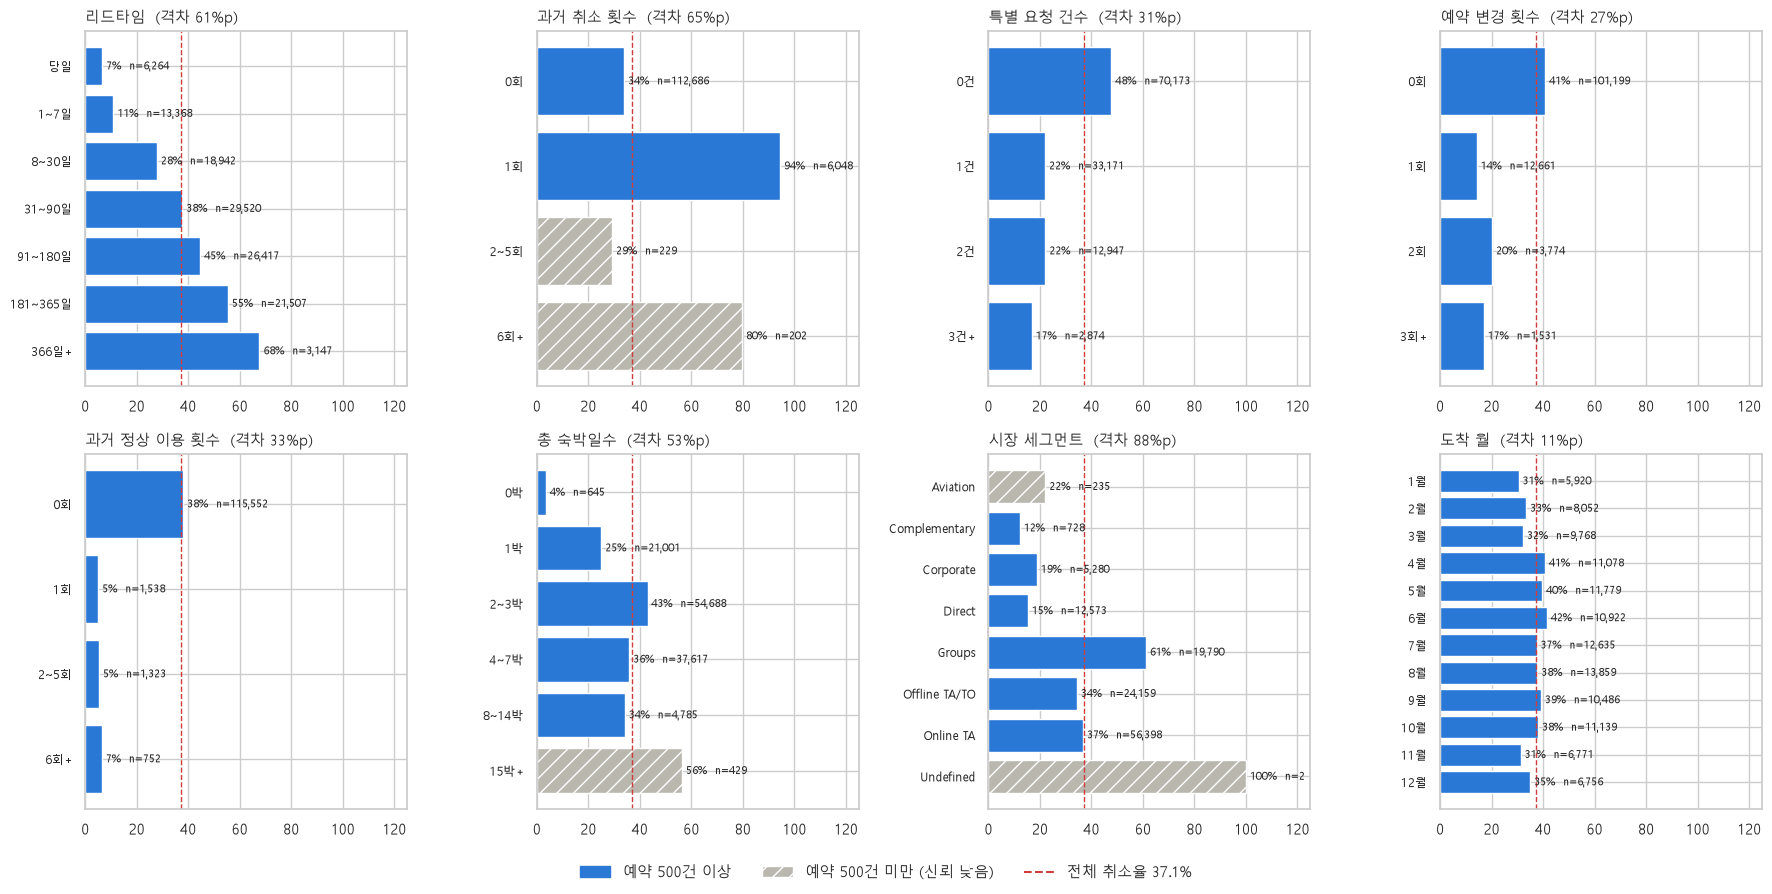

In [11]:
# 2×4 막대그래프
fig, axes = plt.subplots(2, 4, figsize=(18, 9))  # 변수 8개를 한 화면에서 비교하기 위해
for ax, (name, t) in zip(axes.ravel(), tables.items()):  # 그래프 칸과 변수를 짝짓기 위해
    t = t.iloc[::-1]  # 첫 구간이 위쪽에 오도록 순서를 뒤집기 위해
    thin = t["예약수"] < MIN_N  # 예약 수가 부족한 구간을 표시하기 위해
    bars = ax.barh(t.index.astype(str), t["취소율"] * 100, color=[GRAY if s else BLUE for s in thin])  # 부족 구간은 회색으로 구분하기 위해
    for bar, s in zip(bars, thin):  # 막대마다 신뢰도를 표시하기 위해
        bar.set_hatch("//" if s else None)  # 색을 못 구분해도 알 수 있도록 빗금 추가
    for i, (rate, n) in enumerate(zip(t["취소율"], t["예약수"])):  # 막대마다 값을 적기 위해
        ax.text(rate * 100 + 1.5, i, f"{rate:.0%}  n={n:,}", va="center", fontsize=8)  # 취소율과 예약 수를 함께 보이기 위해
    ax.axvline(BASE * 100, color=RED, linestyle="--", linewidth=1)  # 전체 취소율과 비교하기 위해
    spread = (t["취소율"].max() - t["취소율"].min()) * 100  # 변수의 영향력을 구간 간 최대 격차로 보기 위해
    ax.set_title(f"{name}  (격차 {spread:.0f}%p)", loc="left", fontsize=11)  # 변수 이름과 격차를 함께 보이기 위해
    ax.set_xlim(0, 125)  # 막대 끝 라벨이 잘리지 않도록
    ax.tick_params(axis="y", labelsize=8.5)  # 구간 이름이 겹치지 않도록

# 공통 범례
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=BLUE),  # 신뢰 가능 막대를 설명하기 위해
    plt.Rectangle((0, 0), 1, 1, facecolor=GRAY, hatch="//"),  # 신뢰 낮은 막대를 설명하기 위해
    Line2D([], [], color=RED, linestyle="--"),  # 기준선을 설명하기 위해
]
legend_labels = [f"예약 {MIN_N}건 이상", f"예약 {MIN_N}건 미만 (신뢰 낮음)", f"전체 취소율 {BASE:.1%}"]  # 범례 문구를 기준값과 맞추기 위해
fig.legend(handles=legend_handles, labels=legend_labels, loc="lower center", ncol=3, frameon=False)  # 8칸에 범례를 반복하지 않도록 하나만
plt.tight_layout(rect=[0, 0.04, 1, 1])  # 아래쪽 범례 공간을 남기기 위해
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
리드타임 당일 7% → 366일+ 68% : 단조 증가, 모든 구간 3천 건 이상 → 믿을 수 있는 추세
특별 요청 · 예약 변경 0 → 1   : 취소율 절반 이하로 하락, 이후 거의 평평
과거 취소 2~5회 29%           : 예약 수 적음(빗금) → 판단 보류
Groups 세그먼트 61%           : 취소율 최고 + 예약 수 많음 → 우선 관리 대상
도착 월                       : 격차 작음 → 계절보다 예약 방식이 더 중요
```

- 핵심: 특별 요청 · 예약 변경은 **많이**가 아니라 **한 번이라도** 하게 만드는 것

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| iloc[::-1] · max() · min() | pandas | 순서 반전 · 최댓값 · 최솟값 | `t["취소율"].max() - t["취소율"].min()` |
| subplots() · barh() · text() · axvline()<br>set_hatch() · Rectangle() · Line2D() | matplotlib | 2×4 칸 · 가로 막대 · 라벨 · 기준선<br>빗금 · 범례 도형 | `plt.subplots(2, 4, ...)` · `ax.barh(...)`<br>`bar.set_hatch("//")` |
| legend() · tight_layout(rect) | matplotlib.figure | 공통 범례 · 범례 공간 확보 | `fig.legend(...)` |
| ravel() | numpy.ndarray | 2×4 축 → 1줄 | `axes.ravel()` |
| zip() · enumerate() | Python 내장 함수 | 짝짓기 · 순번 | `zip(axes.ravel(), tables.items())` |
| A if 조건 else B | Python 기본 문법 | 조건에 따라 값 선택 | `GRAY if s else BLUE` |

### 2-4. 리드타임: 취소 위험은 언제 쌓이는가

**한글 요약**

- 리드타임(예약~도착 일수) 하루 단위 취소율을 **예약 수 가중 이동평균**으로 매끄럽게 정리
- 취소 위험이 가장 빠르게 오르는 구간 확인, 아래 그래프에 리드타임별 예약 수(로그 척도) 표시

**실행 흐름**

1. **입력**: `clean`의 `lead_time` · `is_canceled`
2. **처리**: 리드타임별 예약 · 취소 수 → 상위 0.5% 제외 → 15일 가중 이동평균 → 0 · 30 · 300일 비교
3. **저장**: `lead` (일별 집계 + 이동평균)
4. **출력**: 취소율 곡선 + 예약 수 그래프, 구간별 기울기

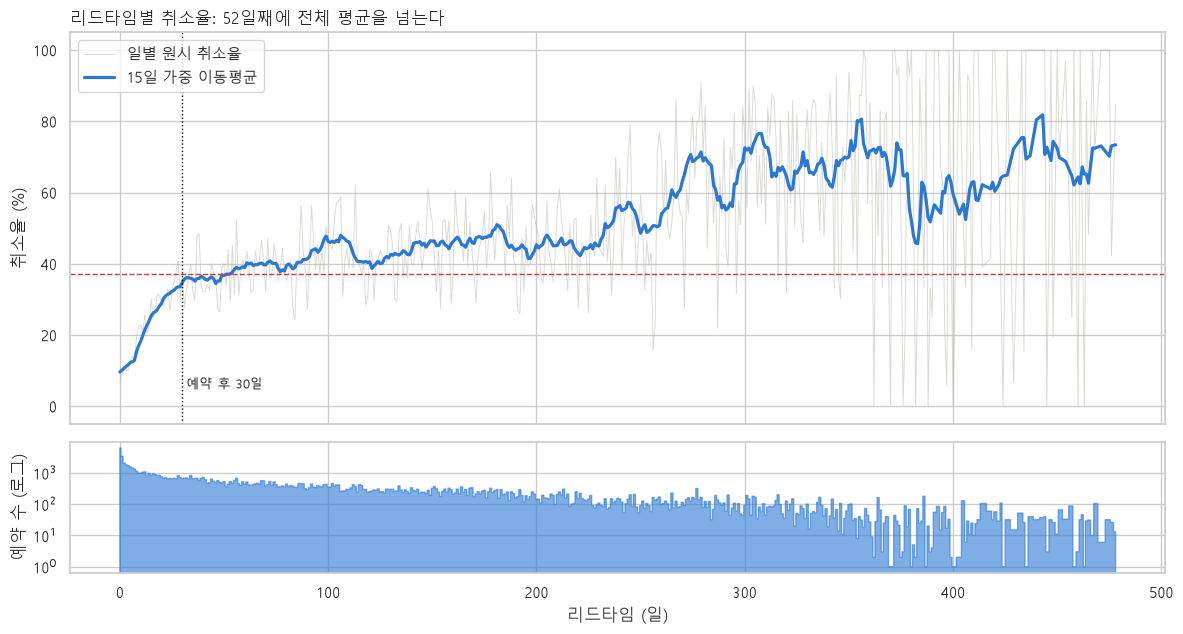

0일 10% → 30일 35% → 300일 73%
첫 30일 기울기: 하루 0.84%p · 30~300일 기울기: 하루 0.14%p


In [12]:
# 리드타임별 집계
lead = clean.groupby("lead_time")["is_canceled"].agg(n="size", canceled="sum")  # 하루 단위로 예약 수와 취소 수를 세기 위해
lead = lead[lead.index <= clean["lead_time"].quantile(0.995)]  # 예약이 극히 드문 상위 0.5%가 곡선을 흔들지 않도록

# 15일 가중 이동평균
window = 15  # 앞뒤 7일 + 당일로 흔들림을 줄이기 위해
rolling_canceled = lead["canceled"].rolling(window, center=True, min_periods=1).sum()  # 구간 취소 수를 더하기 위해
rolling_n = lead["n"].rolling(window, center=True, min_periods=1).sum()  # 구간 예약 수를 더하기 위해
lead["smoothed"] = rolling_canceled / rolling_n  # 예약이 적은 날의 흔들림을 줄이기 위해 예약 수 가중 평균
first_over = lead.index[(lead["smoothed"] >= BASE)].min()  # 처음으로 전체 평균을 넘는 날을 찾기 위해

# 위: 취소율 곡선, 아래: 예약 수
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})  # 같은 리드타임 축으로 두 그래프를 맞추기 위해
ax1.plot(lead.index, lead["canceled"] / lead["n"] * 100, color=GRAY, linewidth=0.7, alpha=0.5, label="일별 원시 취소율")  # 이동평균과 흔들림을 비교하기 위해
ax1.plot(lead.index, lead["smoothed"] * 100, color=BLUE, linewidth=2.3, label=f"{window}일 가중 이동평균")  # 추세를 보이기 위해
ax1.axhline(BASE * 100, color=RED, linestyle="--", linewidth=1)  # 전체 취소율과 비교하기 위해
ax1.axvline(30, color="black", linestyle=":", linewidth=1)  # 예약 후 30일 경계를 보이기 위해
ax1.text(32, 5, "예약 후 30일", fontsize=9)  # 경계선의 의미를 알리기 위해
ax1.set_ylabel("취소율 (%)")  # 세로축 단위를 알리기 위해
ax1.set_title(f"리드타임별 취소율: {first_over}일째에 전체 평균을 넘는다", loc="left")  # 핵심 메시지를 제목에 담기 위해
ax1.legend(loc="upper left")  # 선을 구분하기 위해
ax2.fill_between(lead.index, lead["n"], color=BLUE, alpha=0.6, step="mid")  # 리드타임별 예약 수로 신뢰도를 보이기 위해
ax2.set_yscale("log")  # 예약 수 차이가 커서 작은 값도 보이도록 로그 척도
ax2.set_ylabel("예약 수 (로그)")  # 세로축 단위를 알리기 위해
ax2.set_xlabel("리드타임 (일)")  # 공유 가로축 단위를 알리기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

# 구간별 기울기 비교
at = {d: lead["smoothed"].asof(d) * 100 for d in [0, 30, 300]}  # 기울기를 비교하기 위해 0 · 30 · 300일의 이동평균 취소율
print(f"0일 {at[0]:.0f}% → 30일 {at[30]:.0f}% → 300일 {at[300]:.0f}%")  # 리드타임에 따른 변화를 보이기 위해
print(f"첫 30일 기울기: 하루 {(at[30] - at[0]) / 30:.2f}%p · 30~300일 기울기: 하루 {(at[300] - at[30]) / 270:.2f}%p")  # 위험이 쌓이는 속도를 비교하기 위해

**결과 해설**

```
0일 10% → 30일 35% → 300일 73% : 리드타임이 길수록 취소율 상승
첫 30일 기울기 하루 0.84%p     : 가장 가파른 구간
30~300일 기울기 하루 0.14%p    : 약 6분의 1 속도로 완만
```

- 리마인드 · 예약 확정 요청: **예약 후 한 달 안**이 가장 효율적
- 400일 이후 원시 값: 하루 예약이 수십 건뿐이라 크게 흔들림 → 해석 제외

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| groupby() · agg() · quantile()<br>rolling() · sum() · asof() | pandas | 일별 집계 · 상위 0.5% 경계<br>이동 구간 합 · 가장 가까운 값 | `clean.groupby("lead_time")[...].agg(...)`<br>`rolling(window, center=True, min_periods=1)` |
| subplots(sharex) · plot() · fill_between()<br>axhline() · axvline() · set_yscale() | matplotlib | x축 공유 2칸 · 선 · 면적<br>기준선 · 로그 척도 | `plt.subplots(2, 1, sharex=True, ...)`<br>`ax2.set_yscale("log")` |
| print() | Python 내장 함수 | 기울기 출력 | `print(f"첫 30일 기울기 ...")` |
| { ... for ... } | Python 기본 문법 | 0 · 30 · 300일 딕셔너리 | `{d: ... for d in [0, 30, 300]}` |

---
## 3. 통계 검정: 차이가 우연이 아닌가, 얼마나 큰가

데이터가 10만 건이 넘으면 아주 작은 차이도 p값이 0에 가까워짐 → **p값(유의성)과 효과 크기(얼마나 큰가)를 함께** 확인.

### 3-1. 범주형 변수: 카이제곱 검정 + Cramér's V

**한글 요약**

범주형 변수 9개와 취소 여부의 **관련성** 검정. 카이제곱 검정으로 유의성, Cramér's V(0~1, 클수록 관련 강함)로 효과 크기 측정.

<img src="images/m2_tests.png" alt="p값과 효과 크기의 역할, 변수별 Cramér's V" width="837">

**실행 흐름**

1. **입력**: 2-3의 구간 변수 · `clean`의 범주형 변수
2. **처리**: Cramér's V 함수 → 변수별 교차표 → 카이제곱 검정 → 효과 크기
3. **저장**: `chi_result`
4. **출력**: 효과 크기 큰 순 검정 표

In [13]:
# 효과 크기 함수
def cramers_v(table: pd.DataFrame) -> float:  # 표 크기가 달라도 관련성 크기를 비교하기 위해
    """교차표의 Cramér's V (0 = 무관, 1 = 완전 관련)"""
    chi2 = chi2_contingency(table)[0]  # 정규화에 쓸 카이제곱 통계량을 얻기 위해
    n = table.to_numpy().sum()  # 전체 예약 수로 나누기 위해
    return float(np.sqrt(chi2 / n / (min(table.shape) - 1)))  # 표 크기와 무관하게 0~1로 맞추기 위해

# 검정 대상 범주형 변수
categorical_tests = {  # 2장에서 본 변수를 같은 방식으로 검정하기 위해
    "리드타임 구간": grouped["리드타임"],  # 숫자 대신 2-3 구간을 써서 교차표를 만들기 위해
    "시장 세그먼트": clean["market_segment"],  # 예약 경로의 영향을 보기 위해
    "예약 유통 채널": clean["distribution_channel"],  # 세그먼트와 비슷한 채널 정보도 비교하기 위해
    "특별 요청 건수": grouped["특별 요청 건수"],  # 2-3 구간을 그대로 쓰기 위해
    "과거 취소 횟수": grouped["과거 취소 횟수"],  # 2-3 구간을 그대로 쓰기 위해
    "예약 변경 횟수": grouped["예약 변경 횟수"],  # 2-3 구간을 그대로 쓰기 위해
    "호텔 유형": clean["hotel"],  # 시티 · 리조트 차이를 보기 위해
    "식사 옵션": clean["meal"],  # 관련성이 작은 변수와 비교하기 위해
    "도착 월": clean["arrival_date_month"],  # 계절 효과가 작은지 확인하기 위해
}  # 2장에서 본 변수를 같은 방식으로 검정하기 위해

# 변수별 검정
chi_rows = []  # 변수 1개를 표 1행으로 모으기 위해
for name, key in categorical_tests.items():  # 변수를 하나씩 검정하기 위해
    table = pd.crosstab(key, clean["is_canceled"])  # 카이제곱 검정에 쓸 범주 × 취소 여부 교차표를 만들기 위해
    chi2, p, dof, _ = chi2_contingency(table)  # 통계량 · p값 · 자유도를 얻기 위해 (기대빈도는 미사용)
    chi_rows.append({"변수": name, "카이제곱": chi2, "자유도": dof, "p값": p, "Cramér's V": cramers_v(table)})  # 유의성과 효과 크기를 함께 기록하기 위해
chi_result = pd.DataFrame(chi_rows).set_index("변수").sort_values("Cramér's V", ascending=False)  # 효과 크기가 큰 순으로 보기 위해

# 결과 표
(chi_result.style  # 서식과 막대를 이어서 적용하기 위해
 .format({"카이제곱": "{:,.0f}", "p값": "{:.1e}", "Cramér's V": "{:.3f}"})  # 아주 작은 p값을 읽을 수 있도록 지수 표기
 .bar(subset=["Cramér's V"], color="#9ecae1"))  # 효과 크기를 셀 안 막대로 비교하기 위해

,카이제곱,자유도,p값,Cramér's V
변수,,,,
리드타임 구간,"12,121",6,0.0e+00,0.319
과거 취소 횟수,"9,171",3,0.0e+00,0.277
시장 세그먼트,"8,509",7,0.0e+00,0.267
특별 요청 건수,"8,397",3,0.0e+00,0.265
예약 변경 횟수,"4,177",3,0.0e+00,0.187
예약 유통 채널,"3,752",4,0.0e+00,0.177
호텔 유형,"2,243",1,0.0e+00,0.137
도착 월,583,11,7.1e-118,0.070
식사 옵션,231,3,1.0e-49,0.044


**결과 해설**

```
리드타임 구간 0.319                                : 관련성 가장 큼
과거 취소 0.277 · 세그먼트 0.267 · 특별 요청 0.265 : 관련성 큼
도착 월 0.070 · 식사 옵션 0.044                    : 관련성 작음
p값 모두 0에 가까움                                : 데이터가 많아 유의성만으로는 구분 불가 → 효과 크기로 판단
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| cramers_v() | 사용자 정의 함수 | 효과 크기 계산 | `cramers_v(table)` |
| chi2_contingency() | scipy.stats | 교차표 독립성 검정 | `chi2_contingency(table)` |
| crosstab() · DataFrame() | pandas | 교차표 · 결과 표 | `pd.crosstab(key, clean["is_canceled"])` |
| to_numpy() · shape · style.bar() | pandas.DataFrame | 배열 변환 · 크기 · 셀 안 막대 | `.bar(subset=["Cramér's V"], ...)` |
| sqrt() · min() · float() | numpy · 내장 함수 | 제곱근 · 작은 쪽 · 실수 | `np.sqrt(chi2 / n / (min(table.shape) - 1))` |
| 튜플 언패킹 · _ | Python 기본 문법 | 검정 결과 4개 분리 | `chi2, p, dof, _ = ...` |

### 3-2. 수치형 변수: Mann–Whitney U + Holm 보정

**한글 요약**

- 수치형 변수 7개에서 **취소 그룹과 유지 그룹의 분포 차이** 검정
- 값이 한쪽으로 치우쳐 평균 비교(t-검정) 대신 순위 기반 Mann–Whitney U 사용, 여러 번 검정하므로 Holm 보정
- 효과 크기(rank-biserial): -1~+1, **+는 취소 그룹 값이 더 큼**

**실행 흐름**

1. **입력**: `clean`의 수치형 변수 7개
2. **처리**: Holm 보정 함수 → 취소 · 유지 그룹 분리 → Mann–Whitney U → rank-biserial → 보정 p값
3. **저장**: `mw_result`
4. **출력**: 효과 크기 절댓값 큰 순 검정 표

In [14]:
# 다중비교 보정 함수
def holm(p_values: np.ndarray) -> np.ndarray:  # 여러 번 검정할 때 우연한 유의를 막기 위해
    """Holm 보정: 작은 p값부터 (남은 검정 수)를 곱해 보수적으로 조정"""
    order = np.argsort(p_values)  # 작은 p값부터 처리하기 위해
    adjusted = np.empty_like(p_values)  # 원래 순서대로 결과를 담기 위해
    running = 0.0  # 보정 p값이 앞 순위보다 작아지지 않도록
    for rank, idx in enumerate(order):  # 순위마다 남은 검정 수를 곱하기 위해
        running = max(running, min((len(p_values) - rank) * p_values[idx], 1.0))  # p값이 1을 넘지 않도록 제한
        adjusted[idx] = running  # 원래 위치에 저장하기 위해
    return adjusted  # 보정된 p값을 표에 넣기 위해

# 변수별 검정
numeric_tests = ["lead_time", "total_nights", "total_guests", "previous_cancellations",
                 "previous_bookings_not_canceled", "total_of_special_requests", "booking_changes"]  # 치우친 분포를 가진 수치형 변수를 검정하기 위해
mw_rows = []  # 변수 1개를 표 1행으로 모으기 위해
for col in numeric_tests:  # 변수를 하나씩 검정하기 위해
    canceled = clean.loc[clean["is_canceled"].eq(1), col]  # 취소 그룹 값을 나누기 위해
    kept = clean.loc[clean["is_canceled"].eq(0), col]  # 유지 그룹 값을 나누기 위해
    u, p = mannwhitneyu(canceled, kept)  # 평균 대신 순위로 분포 차이를 검정하기 위해
    mw_rows.append({
        "변수": col,  # 어떤 변수인지 보이기 위해
        "유지 중앙값": kept.median(),  # 치우친 분포의 대표값을 보이기 위해
        "취소 중앙값": canceled.median(),  # 두 그룹을 비교하기 위해
        "p값": p,  # 유의성을 기록하기 위해
        "효과 크기 (rank-biserial)": 2 * u / (len(canceled) * len(kept)) - 1,  # U를 -1~+1로 바꿔 크기를 비교하기 위해
    })
mw_result = pd.DataFrame(mw_rows).set_index("변수")  # 변수 이름을 행 이름으로 보기 위해
mw_result["Holm 보정 p값"] = holm(mw_result["p값"].to_numpy())  # 7번 검정한 만큼 보정하기 위해
mw_result = mw_result.sort_values("효과 크기 (rank-biserial)", key=abs, ascending=False)  # 방향과 무관하게 큰 순으로 보기 위해

# 결과 표
mw_result.style.format({"유지 중앙값": "{:g}", "취소 중앙값": "{:g}", "p값": "{:.1e}",
                        "Holm 보정 p값": "{:.1e}", "효과 크기 (rank-biserial)": "{:+.3f}"})  # 효과 방향이 보이도록 부호 표시

,유지 중앙값,취소 중앙값,p값,효과 크기 (rank-biserial),Holm 보정 p값
변수,,,,,
lead_time,45,113,0.0e+00,+0.378,0.0e+00
total_of_special_requests,1,0,0.0e+00,-0.272,0.0e+00
booking_changes,0,0,0.0e+00,-0.137,0.0e+00
previous_cancellations,0,0,0.0e+00,+0.127,0.0e+00
total_guests,2,2,2.4e-66,+0.049,4.8e-66
total_nights,3,3,6.5e-37,+0.043,6.5e-37
previous_bookings_not_canceled,0,0,0.0e+00,-0.041,0.0e+00


**결과 해설**

```
lead_time +0.378                 : 효과 크기 최대, 중앙값 유지 45일 vs 취소 113일
total_of_special_requests -0.272 : 반대 방향, 취소 그룹의 요청 수가 더 적음
Holm 보정 p값                    : 7개 변수 모두 보정 후에도 유의
```

- 2장 탐색적 분석에서 본 패턴이 우연이 아님을 확인
- 관찰 데이터 → **인과관계는 아님**

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| holm() | 사용자 정의 함수 | 다중비교 p값 보정 | `holm(mw_result["p값"].to_numpy())` |
| mannwhitneyu() | scipy.stats | 순위 기반 두 그룹 비교 | `mannwhitneyu(canceled, kept)` |
| argsort() · empty_like() | numpy | 정렬 순서 · 같은 크기 빈 배열 | `np.argsort(p_values)` |
| loc[] · median() · sort_values(key=abs) | pandas | 그룹 선택 · 중앙값 · 절댓값 정렬 | `clean.loc[clean["is_canceled"].eq(1), col]` |
| enumerate() · max() · min() · len() | Python 내장 함수 | 순위 · 최댓값 · 최솟값 · 개수 | `max(running, min(..., 1.0))` |

---
## 4. 예측 모델: 예약 시점 정보만으로 취소를 구분할 수 있는가

목적: 최고 성능이 아니라 **여러 변수를 함께 고려해도 주요 패턴이 유지되는지** 확인. 예약 이후에 생기거나 바뀌는 정보는 모두 제외해 **데이터 누수** 차단.

- `reservation_status`, `reservation_status_date`, `assigned_room_type`: 취소 여부가 정해진 뒤 기록
- `required_car_parking_spaces`: 주차 요청 고객 취소율 0%, 값이 예약 시점에 확정되는지 확인되지 않아 보수적으로 제외
- `booking_changes`, `days_in_waiting_list`: 예약 이후에 바뀌는 값

### 4-1. 모델 2개 교차검증 비교

**한글 요약**

- 예약 시점 변수만으로 학습 · 테스트 데이터 8:2 분할
- **로지스틱 회귀**와 **랜덤 포레스트**를 5겹 교차검증으로 비교
- 전처리(표준화 · 원-핫 인코딩)를 파이프라인에 포함 → 검증 데이터 정보가 학습에 섞이지 않음

**실행 흐름**

1. **입력**: `clean`의 예약 시점 수치형 12개 · 범주형 7개
2. **처리**: 학습 80% · 테스트 20% 분할 → 전처리 + 모델 파이프라인 2개 → 5겹 교차검증
3. **저장**: `X_train` · `X_test` · `y_train` · `y_test` · `models`
4. **출력**: 지표 4개 평균 ± 표준편차 표

In [15]:
# 데이터 준비
numeric_features = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
                    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
                    "total_of_special_requests", "has_agent", "has_company"]  # 누수를 막기 위해 예약 시점 수치형 12개만
categorical_features = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
                        "distribution_channel", "reserved_room_type"]  # 누수를 막기 위해 예약 시점 범주형 7개만
X = clean[numeric_features + categorical_features]  # 모델 입력을 정하기 위해
y = clean["is_canceled"]  # 예측할 정답을 정하기 위해 (1 = 취소)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)  # 학습 · 테스트의 취소 비율을 같게 하기 위해

# 모델 준비
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),  # 단위 차이가 결과를 흔들지 않도록 표준화
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), categorical_features),  # 100건 미만 범주는 '기타'로 묶어 과적합을 막기 위해
])
models = {
    "로지스틱 회귀": Pipeline([
        ("prep", preprocessor),  # 검증 데이터 정보가 섞이지 않도록 전처리를 파이프라인 안에
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),  # 취소 · 유지 불균형을 보정하기 위해
    ]),
    "랜덤 포레스트": Pipeline([
        ("prep", clone(preprocessor)),  # 두 모델이 전처리기를 공유하지 않도록 복제
        ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=RANDOM_STATE)),  # 잎 최소 5건으로 과적합을 줄이기 위해
    ]),
}

# 5겹 교차검증
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # 겹마다 취소 비율을 같게 하기 위해
metrics = ["roc_auc", "recall", "precision", "accuracy"]  # 순위 · 탐지율 · 정밀도 · 정확도를 함께 보기 위해
cv_rows = []  # 모델 1개를 표 1행으로 모으기 위해
for name, model in models.items():  # 두 모델을 같은 분할로 비교하기 위해
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)  # 겹마다 학습 · 검증을 반복하기 위해
    row = {"모델": name}  # 표의 행 이름을 정하기 위해
    for m in metrics:  # 지표마다 평균과 흔들림을 적기 위해
        row[m] = f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}"  # 결과가 안정적인지 보기 위해 평균 ± 표준편차
    cv_rows.append(row)  # 모델 결과를 표에 넣기 위해
pd.DataFrame(cv_rows).set_index("모델")  # 두 모델을 비교하기 위해

,roc_auc,recall,precision,accuracy
모델,,,,
로지스틱 회귀,0.850 ± 0.003,0.767 ± 0.007,0.672 ± 0.006,0.775 ± 0.003
랜덤 포레스트,0.917 ± 0.003,0.804 ± 0.005,0.763 ± 0.005,0.835 ± 0.003


**결과 해설**

```
랜덤 포레스트 ROC-AUC 0.917 ± 0.003 : 로지스틱 회귀 0.850보다 높음 → 최종 모델로 선택
랜덤 포레스트 recall 0.804          : 실제 취소의 약 80% 탐지
랜덤 포레스트 precision 0.763       : 취소 예측 중 약 76%가 실제 취소
표준편차 0.003~0.007                : 겹마다 결과 안정적
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_test_split() · StratifiedKFold()<br>cross_validate() | sklearn.model_selection | 분할 · 비율 유지 5겹<br>교차검증 점수 | `train_test_split(X, y, test_size=0.2, stratify=y, ...)`<br>`cross_validate(model, ...)` |
| ColumnTransformer() · Pipeline() | sklearn.compose · pipeline | 컬럼별 전처리 · 전처리 + 모델 연결 | `Pipeline([("prep", ...), ("clf", ...)])` |
| StandardScaler() · OneHotEncoder() | sklearn.preprocessing | 표준화 · 원-핫 인코딩 | `OneHotEncoder(..., min_frequency=100)` |
| LogisticRegression() · RandomForestClassifier() | sklearn | 선형 모델 · 트리 200개 모델 | `RandomForestClassifier(n_estimators=200, ...)` |
| clone() | sklearn.base | 학습 전 상태 복제 | `clone(preprocessor)` |
| mean() · std() | numpy.ndarray | 5겹 평균 · 표준편차 | `scores[...].mean()` |

### 4-2. 임계값 선택과 테스트 평가

**한글 요약**

- 분류 임계값을 **테스트가 아닌 검증 데이터**에서 F1 기준으로 선택 → 평가의 공정성 유지
- 전체 학습 데이터로 재학습 후, 한 번도 보지 않은 테스트 데이터에서 최종 평가

<img src="images/m2_model.png" alt="분할부터 테스트 1회 평가까지의 순서" width="929">

**실행 흐름**

1. **입력**: 4-1의 랜덤 포레스트 · 학습 · 테스트 데이터
2. **처리**: 학습 데이터를 다시 8:2 분할 → 검증 F1 최대 임계값 → 전체 학습 데이터로 재학습 → 테스트 예측
3. **저장**: `threshold` · `test_proba` · `best` (학습 완료)
4. **출력**: 임계값 · ROC-AUC · 분류 보고서, ROC 곡선 · 혼동행렬

선택한 임계값 0.52 · 테스트 ROC-AUC 0.919

              precision    recall  f1-score   support

          유지      0.876     0.861     0.869     14996
          취소      0.772     0.794     0.782      8837

    accuracy                          0.836     23833
   macro avg      0.824     0.828     0.826     23833
weighted avg      0.837     0.836     0.837     23833



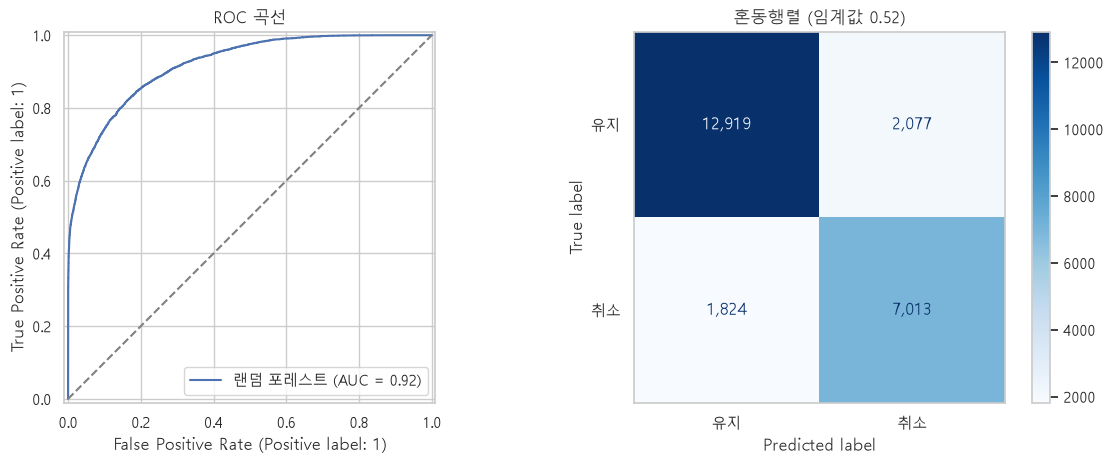

In [16]:
# 임계값 선택 (검증 데이터)
best = models["랜덤 포레스트"]  # 교차검증 ROC-AUC가 높은 모델을 쓰기 위해
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)  # 테스트 데이터를 건드리지 않고 임계값을 고르기 위해
val_proba = clone(best).fit(X_sub, y_sub).predict_proba(X_val)[:, 1]  # 검증 데이터의 취소 확률을 얻기 위해
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)  # 임계값별 정밀도 · 재현율을 얻기 위해
f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)  # 0으로 나누지 않도록 하한을 두고 F1 계산
threshold = float(thresholds[np.argmax(f1)])  # 정밀도와 재현율의 균형이 가장 좋은 임계값을 고르기 위해

# 최종 학습 · 테스트 평가
best.fit(X_train, y_train)  # 더 많은 데이터로 학습하기 위해 전체 학습 데이터로 재학습
test_proba = best.predict_proba(X_test)[:, 1]  # 테스트 데이터의 취소 확률을 얻기 위해
test_pred = (test_proba >= threshold).astype(int)  # 검증에서 고른 임계값으로 취소(1)를 정하기 위해
print(f"선택한 임계값 {threshold:.2f} · 테스트 ROC-AUC {roc_auc_score(y_test, test_proba):.3f}\n")  # 임계값과 순위 성능을 확인하기 위해
print(classification_report(y_test, test_pred, target_names=["유지", "취소"], digits=3))  # 클래스별 지표를 보기 위해

# ROC 곡선 · 혼동행렬
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))  # 두 평가 그래프를 나란히 보기 위해
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0], name="랜덤 포레스트")  # 모든 임계값의 성능을 보기 위해
axes[0].plot([0, 1], [0, 1], "--", color="gray")  # 무작위 추측과 비교하기 위해
axes[0].set_title("ROC 곡선")  # 그래프 내용을 알리기 위해
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["유지", "취소"], cmap="Blues",
                                        ax=axes[1], values_format=",")  # 선택한 임계값의 정답 · 오답 건수를 보기 위해
axes[1].set_title(f"혼동행렬 (임계값 {threshold:.2f})")  # 어떤 임계값인지 알리기 위해
axes[1].grid(False)  # 칸 위 격자가 숫자를 가리지 않도록
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
임계값 0.52          : 검증 데이터 F1 최대 지점
테스트 ROC-AUC 0.919 : 교차검증 0.917과 거의 같음 → 과적합 없음
취소 recall 0.794    : 실제 취소 8,837건 중 약 79% 탐지
취소 precision 0.772 : 취소 예측 중 약 77%가 실제 취소
accuracy 0.836       : 테스트 23,833건 중 83.6% 정답
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| fit() · predict_proba() | sklearn.pipeline.Pipeline | 학습 · 클래스별 확률 | `best.predict_proba(X_test)[:, 1]` |
| precision_recall_curve() · roc_auc_score()<br>classification_report() | sklearn.metrics | 임계값별 정밀도 · 재현율 · ROC-AUC<br>클래스별 지표 표 | `precision_recall_curve(y_val, val_proba)`<br>`classification_report(...)` |
| RocCurveDisplay · ConfusionMatrixDisplay | sklearn.metrics | ROC 곡선 · 혼동행렬 그래프 | `RocCurveDisplay.from_predictions(...)` |
| maximum() · argmax() · astype() | numpy | 0 나누기 방지 · 최댓값 위치 · 1/0 변환 | `np.argmax(f1)` |
| subplots() · plot() · grid() | matplotlib | 1×2 칸 · 기준선 · 격자 끄기 | `axes[1].grid(False)` |
| float() · print() | Python 내장 함수 | 실수 변환 · 출력 | `float(thresholds[np.argmax(f1)])` |

### 4-3. 순열 중요도: 예측에 많이 쓰인 변수

**한글 요약**

변수 하나를 무작위로 섞었을 때 **ROC-AUC가 얼마나 떨어지는지**로 중요도 측정. 계산 시간 단축을 위해 테스트 데이터 8,000건 표본 사용.

**실행 흐름**

1. **입력**: 4-2의 학습된 `best` · 테스트 데이터
2. **처리**: 8,000건 표본 → 변수별 3회 섞기 → ROC-AUC 감소량 평균
3. **저장**: `importance` (상위 10개)
4. **출력**: 순열 중요도 막대그래프

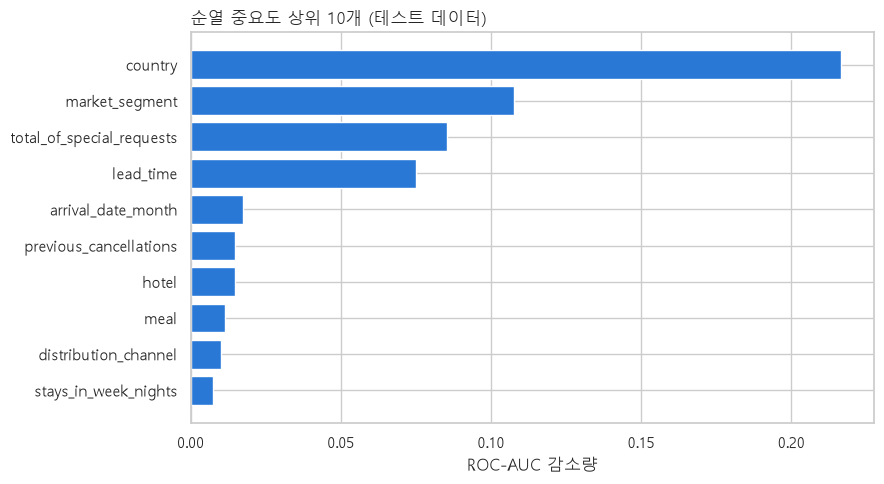

In [17]:
# 순열 중요도 계산
sample = X_test.sample(n=8000, random_state=RANDOM_STATE)  # 계산 시간을 줄이기 위해 재현 가능한 표본
perm = permutation_importance(best, sample, y_test.loc[sample.index], scoring="roc_auc",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)  # 섞는 우연을 줄이기 위해 변수별 3회 평균
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values().tail(10)  # 변수 이름을 붙여 상위 10개만 보기 위해

# 막대그래프
fig, ax = plt.subplots(figsize=(9, 5))  # 그래프 영역을 만들기 위해
ax.barh(importance.index, importance.values, color=BLUE)  # 중요도가 큰 변수가 위쪽에 오도록
ax.set_xlabel("ROC-AUC 감소량")  # 중요도의 의미를 알리기 위해
ax.set_title("순열 중요도 상위 10개 (테스트 데이터)", loc="left")  # 그래프 내용을 알리기 위해
plt.tight_layout()  # 라벨이 겹치지 않도록
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
상위 변수 : 국가 · 시장 세그먼트 · 특별 요청 수 · 리드타임
```

- 탐색적 분석 · 통계 검정 결과와 같은 방향
- 중요도가 높다 ≠ 취소의 **원인** (예측에 많이 쓰였다는 뜻)
- 국가 비중이 유독 큼 → 예약 시점에 확정되는 값인지 데이터 설명만으로 확인 불가 → 4-4에서 국가 제외 모델 점검

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| permutation_importance() | sklearn.inspection | 섞어서 성능 감소량 측정 | `permutation_importance(best, sample, ...)` |
| Series() · sample() · sort_values() · tail() | pandas | 이름 붙이기 · 표본 · 정렬 · 마지막 10개 | `X_test.sample(n=8000, ...)` |
| subplots() · barh() · set_xlabel() | matplotlib | 그래프 영역 · 가로 막대 · 축 이름 | `ax.barh(importance.index, ...)` |

### 4-4. 국가 정보 점검: 국가를 빼도 예측되는가

**한글 요약**

예약 수 상위 5개 국가의 취소율을 확인하고, **국가를 뺀 모델**의 테스트 ROC-AUC와 비교. 국가가 예약 시점 정보인지 확인되지 않으므로 보수적인 기준 확보.

**실행 흐름**

1. **입력**: `clean`의 `country` · 학습 · 테스트 데이터
2. **처리**: 상위 5개 외 '기타'로 묶기 → 국가별 취소율 → 국가 제외 모델 학습 → ROC-AUC 비교
3. **저장**: `model_wo` · `auc_wo`
4. **출력**: 국가별 예약 수 · 취소율 표, 국가 포함 vs 제외 ROC-AUC

In [18]:
# 상위 5개 국가 취소율
top_countries = clean["country"].value_counts().head(5).index  # 예약이 많은 국가만 따로 보기 위해
country_group = clean["country"].where(clean["country"].isin(top_countries), "기타")  # 나머지 국가를 '기타'로 묶기 위해
country_rates = rate_table(country_group).sort_values("예약수", ascending=False)[["예약수", "취소율"]]  # 2장과 같은 방식으로 취소율을 구하기 위해
display(country_rates.style.format({"예약수": "{:,}", "취소율": "{:.1%}"}))  # 읽기 쉽도록 천 단위 · 백분율로

# 국가 제외 모델
no_country = [col for col in categorical_features if col != "country"]  # 국가만 뺀 범주형 변수를 만들기 위해
model_wo = Pipeline([
    ("prep", ColumnTransformer([
        ("num", StandardScaler(), numeric_features),  # 4-1과 같은 수치형 전처리를 쓰기 위해
        ("cat", OneHotEncoder(handle_unknown="ignore"), no_country),  # 학습에 없던 범주가 나와도 오류 없이 0으로 처리하기 위해
    ])),
    ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=RANDOM_STATE)),  # 국가 정보 유무만 다르게 비교하기 위해 4-1과 같은 설정
]).fit(X_train[numeric_features + no_country], y_train)  # 국가 없이 학습하기 위해

# 국가 포함 vs 제외
auc_wo = roc_auc_score(y_test, model_wo.predict_proba(X_test[numeric_features + no_country])[:, 1])  # 국가 제외 모델의 성능을 재기 위해
print(f"테스트 ROC-AUC · 국가 포함 {roc_auc_score(y_test, test_proba):.3f} → 국가 제외 {auc_wo:.3f}")  # 국가 정보의 기여를 비교하기 위해

,예약수,취소율
country,,
PRT,"48,458",56.7%
기타,"32,352",27.6%
GBR,"12,115",20.2%
FRA,"10,400",18.6%
ESP,"8,559",25.4%
DEU,"7,281",16.7%


테스트 ROC-AUC · 국가 포함 0.919 → 국가 제외 0.886


**결과 해설**

```
PRT 56.7%             : 다른 상위 국가(16.7~25.4%)보다 훨씬 높음
ROC-AUC 0.919 → 0.886 : 국가를 빼도 성능이 크게 무너지지 않음
```

- 국가 없이도 **리드타임 · 시장 세그먼트 · 특별 요청**만으로 취소를 상당 부분 구분 가능
- 국가가 예약 시점 정보인지 확인 전까지 **국가 제외 모델(0.886)을 보수적 기준**으로 사용

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| rate_table() | 사용자 정의 함수 | 국가별 예약 수 · 취소율 | `rate_table(country_group)` |
| value_counts() · head() · where() · isin() | pandas.Series | 값별 개수 · 상위 5 · 조건 바꾸기 · 포함 여부 | `.where(clean["country"].isin(top_countries), "기타")` |
| Pipeline() · ColumnTransformer()<br>OneHotEncoder(handle_unknown) | sklearn | 전처리 + 모델 · 컬럼별 전처리<br>처음 보는 범주 처리 | `OneHotEncoder(handle_unknown="ignore")` |
| roc_auc_score() | sklearn.metrics | ROC-AUC | `roc_auc_score(y_test, ...)` |
| display() | IPython.display | 표 출력 | `display(country_rates.style...)` |
| 조건 컴프리헨션 | Python 기본 문법 | 국가만 뺀 목록 | `[col for col in ... if col != "country"]` |

---
## 5. 마무리

### 5-1. 핵심 요인 요약

**한글 요약**

앞에서 계산한 표(`tables`, `binary_summary`)에서 주요 요인 6개의 높은 쪽 · 낮은 쪽 취소율을 꺼내 한 표로 정리. 수치를 직접 입력하지 않고 계산 결과를 참조해 **오기 방지**.

**실행 흐름**

1. **입력**: 2-2의 `binary_summary` · 2-3의 `tables`
2. **처리**: 구간 취소율 조회 함수 → 요인 6개 높은 쪽 · 낮은 쪽 취소율 → 차이(%p)
3. **저장**: `key_findings`
4. **출력**: 핵심 요인 요약 표

In [19]:
# 구간 취소율 조회 함수
def rate(name, label):  # 숫자를 손으로 옮겨 적지 않고 계산 결과에서 바로 꺼내기 위해
    """2-3 구간 표에서 특정 구간의 취소율"""
    return tables[name].loc[label, "취소율"]  # 변수 · 구간 이름으로 취소율을 찾기 위해

# 요인별 높은 쪽 · 낮은 쪽 취소율
past = binary_summary.loc["과거 취소 이력"]  # 2-2 이진 변수 결과를 재사용하기 위해
repeat = binary_summary.loc["재방문 고객"]  # 2-2 이진 변수 결과를 재사용하기 위해
key_findings = pd.DataFrame([  # 요인 6개를 같은 형식으로 비교하기 위해
    ["리드타임", "366일+", rate("리드타임", "366일+"), "당일", rate("리드타임", "당일")],  # 가장 먼 예약과 당일 예약을 비교하기 위해
    ["과거 취소 이력", "있음", past["있음 취소율"], "없음", past["없음 취소율"]],  # 이력 유무를 비교하기 위해
    ["특별 요청", "0건", rate("특별 요청 건수", "0건"), "1건", rate("특별 요청 건수", "1건")],  # 0 → 1건의 차이를 보기 위해
    ["예약 변경", "0회", rate("예약 변경 횟수", "0회"), "1회", rate("예약 변경 횟수", "1회")],  # 0 → 1회의 차이를 보기 위해
    ["재방문 고객", "아님", repeat["없음 취소율"], "재방문", repeat["있음 취소율"]],  # 재방문 여부를 비교하기 위해
    ["시장 세그먼트", "Groups", rate("시장 세그먼트", "Groups"), "Direct", rate("시장 세그먼트", "Direct")],  # 가장 높은 · 낮은 세그먼트를 비교하기 위해
], columns=["요인", "높은 쪽", "취소율 ①", "낮은 쪽", "취소율 ②"])  # 요인 6개를 같은 형식으로 비교하기 위해
key_findings["차이(%p)"] = (key_findings["취소율 ①"] - key_findings["취소율 ②"]) * 100  # 요인별 격차를 %p로 보기 위해

# 결과 표
key_findings.set_index("요인").style.format({"취소율 ①": "{:.1%}", "취소율 ②": "{:.1%}", "차이(%p)": "{:+.1f}"})  # 읽기 쉬운 서식으로 출력하기 위해

,높은 쪽,취소율 ①,낮은 쪽,취소율 ②,차이(%p)
요인,,,,,
리드타임,366일+,67.7%,당일,6.7%,+61.0
과거 취소 이력,있음,91.7%,없음,33.9%,+57.7
특별 요청,0건,47.8%,1건,22.0%,+25.7
예약 변경,0회,40.9%,1회,14.2%,+26.6
재방문 고객,아님,38.0%,재방문,13.1%,+25.0
시장 세그먼트,Groups,61.1%,Direct,15.3%,+45.8


**결과 해설**

```
리드타임 +61.0%p                      : 가장 큰 격차 (366일+ 67.7% vs 당일 6.7%)
과거 취소 이력 +57.7%p                : 이력이 있으면 91.7%가 다시 취소
시장 세그먼트 +45.8%p                 : Groups 61.1% vs Direct 15.3%
특별 요청 +25.7%p · 예약 변경 +26.6%p : 0 → 1 한 번만으로 큰 폭 감소
재방문 고객 +25.0%p                   : 재방문 고객 취소율 13.1%
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| rate() | 사용자 정의 함수 | 구간 취소율 조회 | `rate("리드타임", "366일+")` |
| DataFrame() · loc[] · style.format() | pandas | 표 · 행 이름 조회 · 서식 | `binary_summary.loc["과거 취소 이력"]` |
| def · return | Python 기본 문법 | 함수 정의 · 반환 | `def rate(name, label):` |

### To Do

- **예약 후 30일 안에 리마인드 · 예약 확정 요청**: 취소 위험이 예약 직후 한 달에 가장 빠르게 증가
- **특별 요청 · 옵션 선택을 쉽게 만드는 예약 흐름** (조식 · 룸 업그레이드 1회 제안 등): 요청 · 변경을 한 번이라도 한 고객은 취소율 절반 이하
- **재방문 혜택** (다음 예약 할인 쿠폰): 재방문 고객 취소율 약 13%로 매우 낮음
- **과거 취소 이력 고객에게 보증금 · 확정 절차 적용**: 과거 취소 이력이 있으면 약 92%가 다시 취소
- **Groups 세그먼트 관리 강화** (단체 예약 중간 확인): 취소율 61% + 예약 수 많음

### Not To Do

- **계절 할인 · 성수기 행사로 취소 감소 시도 X**: 도착 월에 따른 취소율 차이 작음
- **예약 변경 제한 X**: 변경한 고객이 오히려 덜 취소
- **예약 수가 적은 범주의 극단적인 취소율만 보고 정책 변경 X**
- **값이 언제 확정되는지 확인되지 않은 변수(주차 요청 등)를 확인 없이 예측 변수로 사용 X**

### 한계

- 관찰 데이터 → 상관관계일 뿐 **인과관계 아님**, 제안의 효과는 A/B 테스트로 검증 필요
- 객실 가격(ADR) · 보증금 유형 같은 중요 변수 부재 → 설명력 한계
- 예약 ID 부재 → 중복 행이 실제 중복 예약인지 확인 불가

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 데이터 품질** | 결측 의미 해석, 규칙 10개 점검, 민감도 확인 | 제거 225건 · 보정 782건, 정제 전후 취소율 37.04 → 37.08% |
| **2. 탐색적 분석** | 이진 · 구간 · 리드타임 취소율 (예약 수 · 신뢰구간 표시) | 리드타임 7 → 68%, 과거 취소 이력 92%, 주차 요청 0%(시점 확인 필요) |
| **3. 통계 검정** | 카이제곱 + Cramér's V, Mann–Whitney U + Holm | 리드타임 V 0.319 · rank-biserial +0.378 |
| **4. 예측 모델** | 예약 시점 변수만, 검증 데이터로 임계값 | 테스트 ROC-AUC 0.919, 국가 제외 0.886 |
| **5. 마무리** | 요인 6개 요약, To Do / Not To Do | 예약 후 30일 리마인드 · 요청 유도 · 보증금 |